In [1]:
import os, gc, re, json, time, html, random, unicodedata, warnings
from typing import List, Dict, Optional, Tuple, Any
from collections import Counter, defaultdict
from difflib import SequenceMatcher

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              precision_recall_curve, roc_curve, auc)

from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                           TrainingArguments, Trainer, EarlyStoppingCallback,
                           TrainerCallback, pipeline as hf_pipeline)
from sentence_transformers import SentenceTransformer, CrossEncoder
from rank_bm25 import BM25Okapi
import faiss
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


In [2]:
os.environ["HF_HUB_ETAG_TIMEOUT"] = "30"
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "60"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"

try:
    import hf_transfer
    os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"
except ImportError:
    pass

In [3]:
def load_with_retry(load_fn, *args, max_retries=8, base_wait=10, max_wait=120, **kwargs):
    last_exc = None
    for attempt in range(1, max_retries + 1):
        try:
            return load_fn(*args, **kwargs)
        except Exception as e:
            last_exc = e
            error_name = type(e).__name__
            is_transient = (
                isinstance(e, (ConnectionError, TimeoutError))
                or "504" in str(e) or "502" in str(e) or "503" in str(e)
                or "Timeout" in error_name or "Connection" in error_name
                or "LocalEntryNotFoundError" in error_name
            )
            if not is_transient:
                print(f"Non-transient error ({error_name}), not retrying: {e}")
                raise
            if attempt == max_retries:
                raise
            wait = min(max_wait, base_wait * (2 ** (attempt - 1))) + random.uniform(0, 5)
            print(f"Transient load error (attempt {attempt}/{max_retries}): {error_name}. Retrying in {wait:.0f}s...")
            time.sleep(wait)
    raise last_exc

LOCAL_MODEL_PATHS = {}

def load_tokenizer_and_model_with_retry(model_name: str, num_labels: int = 2, trust_remote_code: bool = False):
    local_path = LOCAL_MODEL_PATHS.get(model_name)
    if local_path and os.path.exists(local_path):
        tokenizer = AutoTokenizer.from_pretrained(local_path, local_files_only=True)
        model = AutoModelForSequenceClassification.from_pretrained(local_path, num_labels=num_labels, local_files_only=True)
        return tokenizer, model
    tokenizer = load_with_retry(AutoTokenizer.from_pretrained, model_name, trust_remote_code=trust_remote_code)
    model = load_with_retry(AutoModelForSequenceClassification.from_pretrained, model_name,
                             num_labels=num_labels, trust_remote_code=trust_remote_code)
    return tokenizer, model

In [4]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

DATA_ROOT = r"C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer"

PATHS = {
    "train_a": f"{DATA_ROOT}/SubtaskA/Train/train_subtask1.json",
    "dev_a": f"{DATA_ROOT}/SubtaskA/Train/dev_subtask1.json",
    "evidence_pool": f"{DATA_ROOT}/SubtaskA/Train/evidence_pool.json",
    "evidence_pool_test": f"{DATA_ROOT}/SubtaskA/Test/evidence_pool_test.json",
    "test_a": {
        "english": f"{DATA_ROOT}/SubtaskA/Test/subtask1_english_test.json",
        "hindi": f"{DATA_ROOT}/SubtaskA/Test/subtask1_hindi_test.json",
        "bengali": f"{DATA_ROOT}/SubtaskA/Test/subtask1_bengali_test.json",
        "codemix": f"{DATA_ROOT}/SubtaskA/Test/subtask1_codemix_test.json",
    },
    "dev_b": f"{DATA_ROOT}/SubtaskB/Train/dev_subtask2.json",
    "test_b": {
        "english": f"{DATA_ROOT}/SubtaskB/Test/subtask2_english_test.json",
        "hindi": f"{DATA_ROOT}/SubtaskB/Test/subtask2_hindi_test.json",
        "bengali": f"{DATA_ROOT}/SubtaskB/Test/subtask2_bengali_test.json",
        "codemix": f"{DATA_ROOT}/SubtaskB/Test/subtask2_codemix_test.json",
    },
}

COL_ID, COL_CLAIM, COL_EVIDENCE, COL_LABEL = "ID", "Text", "Evidence", "Label"
LABEL2ID = {"SUPPORTS": 0, "REFUTES": 1}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
LANG_LABEL = {"english": "English", "hindi": "Hindi", "bengali": "Bengali", "codemix": "CodeMix"}

MODEL_CONFIGS = {
    "xlm-roberta-base": {"name": "xlm-roberta-base", "max_len": 256, "lr": 3e-5, "batch_size": 16},
    "muril": {"name": "google/muril-base-cased", "max_len": 256, "lr": 2e-5, "batch_size": 16},
    "indicbert-v2": {"name": "ai4bharat/IndicBERTv2-MLM-only", "max_len": 256, "lr": 2e-5, "batch_size": 16},
}

EMBEDDING_MODELS = [
    "BAAI/bge-m3",
    "intfloat/multilingual-e5-base",
    "sentence-transformers/paraphrase-multilingual-mpnet-base-v2",
]

RERANKER_MODEL = "cross-encoder/ms-marco-MiniLM-L-12-v2"
RAG_GENERATOR_MODEL = "google/mt5-base"

# How many top approaches to produce full submission files for.
TOP_N_APPROACHES = 3

In [5]:
def verify_paths(paths_dict, prefix=""):
    all_ok = True
    for key, val in paths_dict.items():
        if isinstance(val, dict):
            if not verify_paths(val, prefix=f"{prefix}{key}."):
                all_ok = False
        else:
            exists = os.path.exists(val)
            print(f"[{'OK' if exists else 'MISSING'}] {prefix}{key}: {val}")
            if not exists:
                all_ok = False
    return all_ok

paths_ok = verify_paths(PATHS)

[OK] train_a: C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/SubtaskA/Train/train_subtask1.json
[OK] dev_a: C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/SubtaskA/Train/dev_subtask1.json
[OK] evidence_pool: C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/SubtaskA/Train/evidence_pool.json
[OK] evidence_pool_test: C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/SubtaskA/Test/evidence_pool_test.json
[OK] test_a.english: C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/SubtaskA/Test/subtask1_english_test.json
[OK] test_a.hindi: C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/SubtaskA/Test/subtask1_hindi_test.json
[OK] test_a.bengali: C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/SubtaskA/Test/subtask1_bengali_test.json
[OK] test_a.codemix: C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/SubtaskA/Test/subtask1_codemix_test.json
[OK] dev_b: C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/SubtaskB/Train/dev_subtask2.json
[OK] test_b.english: C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/SubtaskB/Test/subta

In [6]:
import os, json
import pandas as pd
import numpy as np
from collections import Counter

def load_json_safe(path):
    if not os.path.exists(path):
        print(f"  [MISSING] {path}")
        return None
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

def to_df_safe(records):
    if records is None:
        return pd.DataFrame()
    if isinstance(records, dict):
        for key in ["data", "records", "items"]:
            if key in records and isinstance(records[key], list):
                records = records[key]
                break
        else:
            records = [records]
    return pd.DataFrame(records)

print("=" * 70)
print("SUBTASK A (Evidence Selection + Veracity Prediction)")
print("=" * 70)

train_a = to_df_safe(load_json_safe(PATHS["train_a"]))
dev_a = to_df_safe(load_json_safe(PATHS["dev_a"]))

for name, df in [("Train", train_a), ("Dev", dev_a)]:
    print(f"\n--- {name} ---")
    if df.empty:
        print("  No data loaded.")
        continue
    print(f"  Total records: {len(df)}")
    if COL_LABEL in df.columns:
        print(f"  Label distribution: {dict(df[COL_LABEL].value_counts())}")
    if COL_CLAIM in df.columns:
        claim_lens = df[COL_CLAIM].astype(str).apply(lambda x: len(x.split()))
        print(f"  Claim length (words): min={claim_lens.min()}, max={claim_lens.max()}, "
              f"mean={claim_lens.mean():.1f}, median={claim_lens.median():.0f}")
        dup_claims = df[COL_CLAIM].duplicated().sum()
        print(f"  Duplicate claims: {dup_claims}")
    if COL_EVIDENCE in df.columns:
        ev_lens = df[COL_EVIDENCE].astype(str).apply(lambda x: len(x.split()))
        print(f"  Gold evidence length (words): min={ev_lens.min()}, max={ev_lens.max()}, "
              f"mean={ev_lens.mean():.1f}, median={ev_lens.median():.0f}")
        dup_ev = df[COL_EVIDENCE].duplicated().sum()
        print(f"  Duplicate evidence texts: {dup_ev}")

print("\n--- Evidence Pools ---")
evidence_pool_raw = load_json_safe(PATHS["evidence_pool"])
evidence_pool_test_raw = load_json_safe(PATHS["evidence_pool_test"])

def pool_size(raw):
    if raw is None:
        return 0
    if isinstance(raw, list):
        return len(raw)
    if isinstance(raw, dict):
        for key in ["evidence_pool", "evidences", "evidence", "data", "pool", "records"]:
            if key in raw and isinstance(raw[key], list):
                return len(raw[key])
        return len(raw)
    return 0

print(f"  Train evidence_pool.json: {pool_size(evidence_pool_raw)} entries")
print(f"  Test evidence_pool_test.json: {pool_size(evidence_pool_test_raw)} entries")

print("\n--- Subtask A Test Files (per language) ---")
test_a_stats = []
for lang, path in PATHS["test_a"].items():
    raw = load_json_safe(path)
    df = to_df_safe(raw)
    n = len(df)
    test_a_stats.append({"language": lang, "count": n})
    print(f"  {LANG_LABEL[lang]}: {n} claims" + (f" | columns: {list(df.columns)}" if n else ""))

test_a_df = pd.DataFrame(test_a_stats)
print(f"\n  Total Subtask A test claims across all languages: {test_a_df['count'].sum()}")

print("\n" + "=" * 70)
print("SUBTASK B (End-to-End Claim Verification)")
print("=" * 70)

dev_b = to_df_safe(load_json_safe(PATHS["dev_b"]))
print(f"\n--- Dev ---")
if not dev_b.empty:
    print(f"  Total records: {len(dev_b)}")
    print(f"  Columns: {list(dev_b.columns)}")
else:
    print("  No data loaded.")

print("\n--- Subtask B Test Files (per language) ---")
test_b_stats = []
for lang, path in PATHS["test_b"].items():
    raw = load_json_safe(path)
    df = to_df_safe(raw)
    n = len(df)
    test_b_stats.append({"language": lang, "count": n})
    print(f"  {LANG_LABEL[lang]}: {n} claims" + (f" | columns: {list(df.columns)}" if n else ""))

test_b_df = pd.DataFrame(test_b_stats)
print(f"\n  Total Subtask B test claims across all languages: {test_b_df['count'].sum()}")

print("\n" + "=" * 70)
print("SUMMARY TABLE")
print("=" * 70)

summary_rows = [
    {"Split": "Train (Subtask A)", "Count": len(train_a)},
    {"Split": "Dev (Subtask A)", "Count": len(dev_a)},
    {"Split": "Evidence Pool (train)", "Count": pool_size(evidence_pool_raw)},
    {"Split": "Evidence Pool (test)", "Count": pool_size(evidence_pool_test_raw)},
]
for lang in PATHS["test_a"]:
    summary_rows.append({"Split": f"Test A - {LANG_LABEL[lang]}", "Count": test_a_stats[list(PATHS['test_a'].keys()).index(lang)]["count"]})
summary_rows.append({"Split": "Dev (Subtask B)", "Count": len(dev_b)})
for lang in PATHS["test_b"]:
    summary_rows.append({"Split": f"Test B - {LANG_LABEL[lang]}", "Count": test_b_stats[list(PATHS['test_b'].keys()).index(lang)]["count"]})

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

SUBTASK A (Evidence Selection + Veracity Prediction)

--- Train ---
  Total records: 4536
  Label distribution: {'SUPPORTS': 3040, 'REFUTES': 1496}
  Claim length (words): min=6, max=41, mean=15.6, median=15
  Duplicate claims: 1
  Gold evidence length (words): min=3, max=323, mean=112.5, median=103
  Duplicate evidence texts: 1043

--- Dev ---
  Total records: 1134
  Label distribution: {'SUPPORTS': 741, 'REFUTES': 393}
  Claim length (words): min=6, max=38, mean=15.4, median=14
  Duplicate claims: 0
  Gold evidence length (words): min=25, max=323, mean=110.1, median=100
  Duplicate evidence texts: 67

--- Evidence Pools ---
  Train evidence_pool.json: 13333 entries
  Test evidence_pool_test.json: 28618 entries

--- Subtask A Test Files (per language) ---
  English: 1200 claims | columns: ['ID', 'Text']
  Hindi: 1200 claims | columns: ['ID', 'Text']
  Bengali: 1200 claims | columns: ['ID', 'Text']
  CodeMix: 300 claims | columns: ['ID', 'Text']

  Total Subtask A test claims across al

,Split,Count
0,Train (Subtask A),4536
1,Dev (Subtask A),1134
2,Evidence Pool (train),13333
3,Evidence Pool (test),28618
4,Test A - English,1200
5,Test A - Hindi,1200
6,Test A - Bengali,1200
7,Test A - CodeMix,300
8,Dev (Subtask B),631
9,Test B - English,299


In [7]:
def cleanup(*objs):
    for o in objs:
        try:
            del o
        except NameError:
            pass
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        if hasattr(torch.cuda, "ipc_collect"):
            torch.cuda.ipc_collect()
        torch.cuda.synchronize()

def gpu_mem_report(tag=""):
    if torch.cuda.is_available():
        alloc = torch.cuda.memory_allocated() / 1e9
        reserved = torch.cuda.memory_reserved() / 1e9
        print(f"[{tag}] GPU allocated: {alloc:.2f} GB | reserved: {reserved:.2f} GB")

def safe_train_step(trainer_fn, batch_size, grad_accum, max_len, max_retries=5):
    attempt = 0
    while attempt < max_retries:
        try:
            return trainer_fn(batch_size=batch_size, grad_accum=grad_accum, max_len=max_len)
        except torch.cuda.OutOfMemoryError:
            attempt += 1
            cleanup()
            if batch_size > 1:
                batch_size = max(1, batch_size // 2)
                grad_accum *= 2
            elif max_len > 64:
                max_len = int(max_len * 0.75)
            else:
                return None
    return None

In [8]:
preload_failures = []
for model_key, config in MODEL_CONFIGS.items():
    try:
        tok, mdl = load_tokenizer_and_model_with_retry(config["name"])
        del tok, mdl
        cleanup()
        print(f"Cached: {model_key}")
    except Exception as e:
        print(f"Failed to cache {model_key}: {e}")
        preload_failures.append(model_key)

if preload_failures:
    print(f"Could not pre-cache: {preload_failures}")

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Cached: xlm-roberta-base


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/muril-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Cached: muril


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-only and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Cached: indicbert-v2


In [9]:
def load_json(path: str) -> Any:
    if not os.path.exists(path):
        print(f"Missing file: {path}")
        return []
    try:
        with open(path, "r", encoding="utf-8") as f:
            return json.load(f)
    except json.JSONDecodeError:
        return []
    except UnicodeDecodeError:
        with open(path, "r", encoding="utf-8", errors="ignore") as f:
            return json.load(f)

def to_df(records) -> pd.DataFrame:
    if isinstance(records, dict):
        for key in ["data", "records", "items"]:
            if key in records and isinstance(records[key], list):
                records = records[key]
                break
        else:
            records = [records]
    return pd.DataFrame(records)

In [10]:
class EvidencePool:
    def __init__(self, records: List[dict]):
        self.id2text, self.id2lang = {}, {}
        for r in records:
            eid = str(r.get("evidence_id", r.get("id", "")))
            text = r.get("evidence", r.get("text", ""))
            if not eid or not text:
                continue
            self.id2text[eid] = text
            self.id2lang[eid] = r.get("language", "unknown")
        self.ids = list(self.id2text.keys())
        self.texts = [self.id2text[i] for i in self.ids]

    def get(self, eid): return self.id2text.get(str(eid), "")


def _normalize_pool_records(raw) -> List[dict]:
    if isinstance(raw, dict):
        for key in ["evidence_pool", "evidences", "evidence", "data", "pool", "records"]:
            if key in raw and isinstance(raw[key], list):
                raw = raw[key]
                break
        else:
            if raw and all(isinstance(v, str) for v in raw.values()):
                return [{"evidence_id": k, "evidence": v} for k, v in raw.items()]
            raw = [raw]

    if not isinstance(raw, list):
        return []

    records = []
    for i, item in enumerate(raw):
        if isinstance(item, str):
            records.append({"evidence_id": str(i), "evidence": item})
            continue
        if not isinstance(item, dict):
            continue
        eid = (item.get("evidence_id") or item.get("id") or item.get("ID")
               or item.get("Evidence_ID") or item.get("evidenceId") or str(i))
        text = (item.get("evidence") or item.get("Evidence") or item.get("text")
                or item.get("Text") or item.get("evidence_text") or item.get("content") or "")
        lang = item.get("language") or item.get("Language") or item.get("lang") or "unknown"
        records.append({"evidence_id": str(eid), "evidence": text, "language": lang})
    return records


def load_evidence_pool_robust(path: str) -> EvidencePool:
    return EvidencePool(_normalize_pool_records(load_json(path)))


def build_pool_from_gold_evidence(*dfs, text_col=COL_EVIDENCE) -> EvidencePool:
    seen, seen_texts, counter = {}, set(), 0
    for df in dfs:
        if df is None or text_col not in df.columns:
            continue
        for txt in df[text_col].dropna().unique():
            txt = str(txt).strip()
            if txt and txt not in seen_texts:
                seen[str(counter)] = txt
                seen_texts.add(txt)
                counter += 1
    return EvidencePool([{"evidence_id": k, "evidence": v} for k, v in seen.items()])

In [11]:
train_raw = load_json(PATHS["train_a"])
dev_raw = load_json(PATHS["dev_a"])
train_df = to_df(train_raw)
dev_df = to_df(dev_raw)

print(f"Train: {len(train_df)} | Dev: {len(dev_df)}")

evidence_pool = load_evidence_pool_robust(PATHS["evidence_pool"])
evidence_pool_test = load_evidence_pool_robust(PATHS["evidence_pool_test"])

MIN_POOL_SIZE = 10
if len(evidence_pool.ids) < MIN_POOL_SIZE:
    evidence_pool = build_pool_from_gold_evidence(train_df, dev_df, text_col=COL_EVIDENCE)

TEST_POOL_IS_DEDICATED = len(evidence_pool_test.ids) >= MIN_POOL_SIZE
print(f"Train evidence pool: {len(evidence_pool.ids)} | Test evidence pool: {len(evidence_pool_test.ids)} (dedicated={TEST_POOL_IS_DEDICATED})")

test_a_raw = {lang: load_json(p) for lang, p in PATHS["test_a"].items()}
dev_b_raw = load_json(PATHS["dev_b"])
test_b_raw = {lang: load_json(p) for lang, p in PATHS["test_b"].items()}

Train: 4536 | Dev: 1134
Train evidence pool: 13333 | Test evidence pool: 28618 (dedicated=True)


In [12]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")
HTML_RE = re.compile(r"<.*?>")
EMOJI_RE = re.compile(
    "[\U0001F300-\U0001FAFF\U00002700-\U000027BF\U0001F1E6-\U0001F1FF\U00002600-\U000026FF]+",
    flags=re.UNICODE
)
MULTISPACE_RE = re.compile(r"\s+")

def clean_text(text) -> str:
    if not isinstance(text, str) or not text.strip():
        return ""
    text = html.unescape(text)
    text = HTML_RE.sub(" ", text)
    text = URL_RE.sub(" ", text)
    text = EMOJI_RE.sub(" ", text)
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"([!?.,;:]){2,}", r"\1", text)
    return MULTISPACE_RE.sub(" ", text).strip()

def preprocess_dataframe(df: pd.DataFrame, text_cols: List[str], id_col: Optional[str] = None) -> pd.DataFrame:
    df = df.copy()
    for col in text_cols:
        if col in df.columns:
            df[col] = df[col].astype(str).apply(clean_text)
    primary = text_cols[0]
    df = df[df[primary].str.len() > 0]
    df = df.drop_duplicates(subset=[id_col]) if id_col and id_col in df.columns else df.drop_duplicates(subset=[primary])
    return df.reset_index(drop=True)

train_df = preprocess_dataframe(train_df, [COL_CLAIM, COL_EVIDENCE], id_col=COL_ID)
dev_df = preprocess_dataframe(dev_df, [COL_CLAIM, COL_EVIDENCE], id_col=COL_ID)
evidence_pool.id2text = {k: clean_text(v) for k, v in evidence_pool.id2text.items()}
evidence_pool.texts = [evidence_pool.id2text[i] for i in evidence_pool.ids]

In [13]:
text_to_id = {v: k for k, v in evidence_pool.id2text.items()}

def find_relevant_ids(evidence_text: str) -> List[str]:
    eid = text_to_id.get(evidence_text)
    return [eid] if eid else []

train_df["relevant_evidence_ids"] = train_df[COL_EVIDENCE].apply(find_relevant_ids)
dev_df["relevant_evidence_ids"] = dev_df[COL_EVIDENCE].apply(find_relevant_ids)

In [14]:
def success_at_k(retrieved, relevant, k=3):
    return int(len(set(retrieved[:k]) & set(relevant)) > 0)

def precision_at_k(retrieved, relevant, k=3):
    return len(set(retrieved[:k]) & set(relevant)) / k if k else 0.0

def recall_at_k(retrieved, relevant, k=3):
    return len(set(retrieved[:k]) & set(relevant)) / len(relevant) if relevant else 0.0

def ndcg_at_k(retrieved, relevant, k=3):
    dcg = sum(1.0 / np.log2(i + 2) for i, r in enumerate(retrieved[:k]) if r in relevant)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return dcg / idcg if idcg > 0 else 0.0

def mrr(retrieved, relevant):
    for i, r in enumerate(retrieved):
        if r in relevant:
            return 1.0 / (i + 1)
    return 0.0

def average_precision(retrieved, relevant):
    hits, score = 0, 0.0
    for i, r in enumerate(retrieved):
        if r in relevant:
            hits += 1
            score += hits / (i + 1)
    return score / len(relevant) if relevant else 0.0

def evaluate_retrieval(all_retrieved, all_relevant, k=3):
    metrics = defaultdict(list)
    for retrieved, relevant in zip(all_retrieved, all_relevant):
        if not relevant:
            continue
        metrics["success@k"].append(success_at_k(retrieved, relevant, k))
        metrics["ndcg@k"].append(ndcg_at_k(retrieved, relevant, k))
        metrics["precision@k"].append(precision_at_k(retrieved, relevant, k))
        metrics["recall@k"].append(recall_at_k(retrieved, relevant, k))
        metrics["mrr"].append(mrr(retrieved, relevant))
        metrics["map"].append(average_precision(retrieved, relevant))
    return {k_: float(np.mean(v)) if v else 0.0 for k_, v in metrics.items()}

In [15]:
def build_faiss_index(embeddings: np.ndarray):
    faiss.normalize_L2(embeddings)
    index = faiss.IndexFlatIP(embeddings.shape[1])
    index.add(embeddings)
    return index

def dense_retrieve_topk(claims, model, index, evidence_ids, k=20):
    q_emb = model.encode(claims, convert_to_numpy=True, show_progress_bar=False, batch_size=64)
    faiss.normalize_L2(q_emb)
    scores, idxs = index.search(q_emb, k)
    return [[(evidence_ids[i], float(s)) for i, s in zip(row_i, row_s)] for row_i, row_s in zip(idxs, scores)]

def evaluate_embedding_models(claims, relevant_lists, evidence_texts, evidence_ids) -> pd.DataFrame:
    rows = []
    for model_name in EMBEDDING_MODELS:
        model, ev_emb, index = None, None, None
        try:
            model = load_with_retry(SentenceTransformer, model_name, device=str(device))
            ev_emb = model.encode(evidence_texts, convert_to_numpy=True, show_progress_bar=True, batch_size=64)
            index = build_faiss_index(ev_emb)
            results = dense_retrieve_topk(claims, model, index, evidence_ids, k=3)
            retrieved_ids = [[eid for eid, _ in r] for r in results]
            m = evaluate_retrieval(retrieved_ids, relevant_lists, k=3)
            m["model"] = model_name
            rows.append(m)
        except Exception as e:
            print(f"Failed for {model_name}: {e}")
        finally:
            cleanup(model, ev_emb, index)
    return pd.DataFrame(rows).set_index("model") if rows else pd.DataFrame()

sample_claims = train_df[COL_CLAIM].tolist()[:300]
sample_relevant = train_df["relevant_evidence_ids"].tolist()[:300]

dense_eval_df = evaluate_embedding_models(sample_claims, sample_relevant, evidence_pool.texts, evidence_pool.ids)
best_embedding_model_name = dense_eval_df["ndcg@k"].idxmax() if not dense_eval_df.empty else EMBEDDING_MODELS[0]
print(f"Best embedding model: {best_embedding_model_name}")

Batches:   0%|          | 0/209 [00:00<?, ?it/s]

Batches:   0%|          | 0/209 [00:00<?, ?it/s]

Batches:   0%|          | 0/209 [00:00<?, ?it/s]

Best embedding model: intfloat/multilingual-e5-base


In [16]:
def tokenize_simple(text: str) -> List[str]:
    return text.lower().split()

bm25_corpus = [tokenize_simple(t) for t in evidence_pool.texts]
bm25 = BM25Okapi(bm25_corpus)

tfidf_vectorizer = TfidfVectorizer(max_features=50000, ngram_range=(1, 2))
tfidf_matrix = tfidf_vectorizer.fit_transform(evidence_pool.texts)

def bm25_retrieve(claim: str, k=20):
    scores = bm25.get_scores(tokenize_simple(claim))
    top_idx = np.argsort(scores)[::-1][:k]
    return [(evidence_pool.ids[i], float(scores[i])) for i in top_idx]

In [17]:
def minmax_norm(scores: List[float]) -> List[float]:
    arr = np.array(scores)
    if arr.max() == arr.min():
        return [0.0] * len(arr)
    return ((arr - arr.min()) / (arr.max() - arr.min())).tolist()

def hybrid_retrieve(claim, dense_model, dense_index, k=20, alpha=0.5) -> List[str]:
    dense_res = dense_retrieve_topk([claim], dense_model, dense_index, evidence_pool.ids, k=k)[0]
    bm25_res = bm25_retrieve(claim, k=k)
    dense_scores = {eid: s for eid, s in dense_res}
    bm25_scores = {eid: s for eid, s in bm25_res}
    all_ids = list(set(dense_scores) | set(bm25_scores))
    d_vals = minmax_norm([dense_scores.get(i, 0.0) for i in all_ids])
    b_vals = minmax_norm([bm25_scores.get(i, 0.0) for i in all_ids])
    fused = {i: alpha * d + (1 - alpha) * b for i, d, b in zip(all_ids, d_vals, b_vals)}
    return [eid for eid, _ in sorted(fused.items(), key=lambda x: x[1], reverse=True)[:k]]

def tune_fusion_weight(claims, relevant_lists, dense_model, dense_index, alphas=(0.0, 0.25, 0.5, 0.75, 1.0)):
    best_alpha, best_ndcg = 0.5, -1
    for alpha in alphas:
        retrieved_ids = [hybrid_retrieve(c, dense_model, dense_index, k=3, alpha=alpha) for c in claims]
        m = evaluate_retrieval(retrieved_ids, relevant_lists, k=3)
        if m.get("ndcg@k", 0) > best_ndcg:
            best_ndcg, best_alpha = m["ndcg@k"], alpha
    return best_alpha

best_dense_model = load_with_retry(SentenceTransformer, best_embedding_model_name, device=str(device))
best_ev_emb = best_dense_model.encode(evidence_pool.texts, convert_to_numpy=True, batch_size=64, show_progress_bar=True)
best_index = build_faiss_index(best_ev_emb)
best_alpha = tune_fusion_weight(sample_claims[:100], sample_relevant[:100], best_dense_model, best_index)
print(f"Best fusion alpha: {best_alpha}")

Batches:   0%|          | 0/209 [00:00<?, ?it/s]

Best fusion alpha: 1.0


In [18]:
def reciprocal_rank_fusion(claim, dense_model, dense_index, k=20, rrf_k=60) -> List[str]:
    dense_res = dense_retrieve_topk([claim], dense_model, dense_index, evidence_pool.ids, k=k)[0]
    bm25_res = bm25_retrieve(claim, k=k)
    dense_ranks = {eid: rank for rank, (eid, _) in enumerate(dense_res)}
    bm25_ranks = {eid: rank for rank, (eid, _) in enumerate(bm25_res)}
    all_ids = set(dense_ranks) | set(bm25_ranks)
    rrf_scores = {
        eid: 1.0 / (rrf_k + dense_ranks.get(eid, k + 1)) + 1.0 / (rrf_k + bm25_ranks.get(eid, k + 1))
        for eid in all_ids
    }
    return [eid for eid, _ in sorted(rrf_scores.items(), key=lambda x: x[1], reverse=True)[:k]]

def compare_fusion_strategies(claims, relevant_lists, dense_model, dense_index):
    weighted_retrieved = [hybrid_retrieve(c, dense_model, dense_index, k=3, alpha=best_alpha) for c in claims]
    weighted_metrics = evaluate_retrieval(weighted_retrieved, relevant_lists, k=3)
    rrf_retrieved = [reciprocal_rank_fusion(c, dense_model, dense_index, k=3) for c in claims]
    rrf_metrics = evaluate_retrieval(rrf_retrieved, relevant_lists, k=3)
    print(f"Weighted fusion: ndcg@3={weighted_metrics.get('ndcg@k',0):.4f} | RRF: ndcg@3={rrf_metrics.get('ndcg@k',0):.4f}")
    return "rrf" if rrf_metrics.get("ndcg@k", 0) > weighted_metrics.get("ndcg@k", 0) else "weighted"

best_fusion_strategy = compare_fusion_strategies(sample_claims[:150], sample_relevant[:150], best_dense_model, best_index)
print(f"Selected fusion strategy: {best_fusion_strategy}")

Weighted fusion: ndcg@3=0.5440 | RRF: ndcg@3=0.5406
Selected fusion strategy: weighted


In [19]:
def text_similarity(a: str, b: str) -> float:
    return SequenceMatcher(None, a, b).ratio()

def filter_near_duplicates(candidate_ids: List[str], threshold: float = 0.85) -> List[str]:
    kept, kept_texts = [], []
    for eid in candidate_ids:
        text = evidence_pool.get(eid)
        if any(text_similarity(text, kt) > threshold for kt in kept_texts):
            continue
        kept.append(eid)
        kept_texts.append(text)
    return kept

def mmr_rerank(claim, candidate_ids, relevance_scores, dense_model, top_n=3, lambda_param=0.6) -> List[str]:
    if len(candidate_ids) <= top_n:
        return candidate_ids
    cand_texts = [evidence_pool.get(eid) for eid in candidate_ids]
    cand_emb = dense_model.encode(cand_texts, convert_to_numpy=True, show_progress_bar=False)
    faiss.normalize_L2(cand_emb)
    selected, selected_idx = [], []
    remaining_idx = list(range(len(candidate_ids)))
    while len(selected) < top_n and remaining_idx:
        best_score, best_i = -1e9, None
        for i in remaining_idx:
            relevance = relevance_scores.get(candidate_ids[i], 0.0)
            sim = max((float(np.dot(cand_emb[i], cand_emb[j])) for j in selected_idx), default=0.0)
            score = lambda_param * relevance - (1 - lambda_param) * sim
            if score > best_score:
                best_score, best_i = score, i
        selected.append(candidate_ids[best_i])
        selected_idx.append(best_i)
        remaining_idx.remove(best_i)
    return selected

In [20]:
reranker = load_with_retry(CrossEncoder, RERANKER_MODEL, device=str(device))

def rerank_topk(claim: str, candidate_ids: List[str], top_n=10) -> List[str]:
    if not candidate_ids:
        return []
    pairs = [(claim, evidence_pool.get(eid)) for eid in candidate_ids]
    scores = reranker.predict(pairs, show_progress_bar=False)
    return [eid for eid, _ in sorted(zip(candidate_ids, scores), key=lambda x: x[1], reverse=True)[:top_n]]

def full_retrieval_pipeline(claim: str, top_n=3, use_mmr=True) -> List[str]:
    if best_fusion_strategy == "rrf":
        candidates = reciprocal_rank_fusion(claim, best_dense_model, best_index, k=30)
    else:
        candidates = hybrid_retrieve(claim, best_dense_model, best_index, k=30, alpha=best_alpha)
    candidates = filter_near_duplicates(candidates, threshold=0.85)
    if not candidates:
        return []
    reranked = rerank_topk(claim, candidates, top_n=min(15, len(candidates)))
    if not use_mmr or len(reranked) <= top_n:
        return reranked[:top_n]
    pairs = [(claim, evidence_pool.get(eid)) for eid in reranked]
    scores = reranker.predict(pairs, show_progress_bar=False)
    score_map = {eid: float(s) for eid, s in zip(reranked, scores)}
    return mmr_rerank(claim, reranked, score_map, best_dense_model, top_n=top_n, lambda_param=0.6)

sample_retrieved = [full_retrieval_pipeline(c) for c in tqdm(sample_claims[:100], desc="Retrieval eval")]
final_retrieval_metrics = evaluate_retrieval(sample_retrieved, sample_relevant[:100], k=3)
print("Final retrieval pipeline metrics:", final_retrieval_metrics)

Retrieval eval:   0%|          | 0/100 [00:00<?, ?it/s]

Final retrieval pipeline metrics: {'success@k': 0.48, 'ndcg@k': 0.33594876057143325, 'precision@k': 0.16, 'recall@k': 0.48, 'mrr': 0.2866666666666667, 'map': 0.2866666666666667}


In [21]:
def attach_evidence(df: pd.DataFrame, claim_column: str) -> pd.DataFrame:
    df = df.copy()
    retrieved_all, evidence_texts_all = [], []
    for claim in tqdm(df[claim_column].tolist(), desc="Attaching evidence"):
        top3 = full_retrieval_pipeline(claim, top_n=3)
        retrieved_all.append(top3)
        evidence_texts_all.append([evidence_pool.get(e) for e in top3])
    df["retrieved_evidence_ids"] = retrieved_all
    df["retrieved_evidence_text"] = evidence_texts_all
    return df

train_df = attach_evidence(train_df, COL_CLAIM)
dev_df = attach_evidence(dev_df, COL_CLAIM)
cleanup(best_dense_model, best_ev_emb, best_index, reranker)

Attaching evidence:   0%|          | 0/4536 [00:00<?, ?it/s]

Attaching evidence:   0%|          | 0/1134 [00:00<?, ?it/s]

In [22]:
class VeracityDataset(Dataset):
    def __init__(self, claims, evidences, labels, tokenizer, max_len):
        self.claims, self.evidences, self.labels = claims, evidences, labels
        self.tokenizer, self.max_len = tokenizer, max_len

    def __len__(self): return len(self.claims)

    def __getitem__(self, idx):
        claim = self.claims[idx]
        evidence = " ".join(self.evidences[idx]) if isinstance(self.evidences[idx], list) else self.evidences[idx]
        enc = self.tokenizer(claim, evidence, truncation=True, max_length=self.max_len, padding="max_length")
        item = {k: torch.tensor(v) for k, v in enc.items()}
        if self.labels is not None:
            item["labels"] = torch.tensor(self.labels[idx])
        return item

def build_labels(df: pd.DataFrame) -> List[int]:
    if COL_LABEL not in df.columns:
        return [0] * len(df)
    return [LABEL2ID.get(str(l).strip().upper(), 0) for l in df[COL_LABEL]]

train_claims = train_df[COL_CLAIM].tolist()
dev_claims = dev_df[COL_CLAIM].tolist()
train_evidences = train_df["retrieved_evidence_text"].tolist()
dev_evidences = dev_df["retrieved_evidence_text"].tolist()
train_labels = build_labels(train_df)
dev_labels = build_labels(dev_df)

In [23]:
def compute_classification_metrics(y_true, y_pred, y_prob=None) -> dict:
    y_pred = np.nan_to_num(np.asarray(y_pred), nan=0).astype(int)
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="binary", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="binary", zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }
    per_class = f1_score(y_true, y_pred, average=None, zero_division=0, labels=[0, 1])
    for i, f1_c in enumerate(per_class):
        metrics[f"f1_class_{ID2LABEL.get(i, i)}"] = f1_c
    return metrics

def compute_metrics_fn(eval_pred):
    logits, labels = eval_pred
    logits = np.nan_to_num(logits, nan=0.0, posinf=0.0, neginf=0.0)
    preds = np.argmax(logits, axis=1)
    return {"accuracy": accuracy_score(labels, preds), "macro_f1": f1_score(labels, preds, average="macro", zero_division=0)}

def is_degenerate_model(y_true, y_pred) -> bool:
    y_pred = np.asarray(y_pred)
    if len(np.unique(y_pred)) == 1:
        return True
    return bool(np.any(f1_score(y_true, y_pred, average=None, zero_division=0, labels=[0, 1]) == 0.0))

def plot_confusion_and_curves(y_true, y_pred, y_prob, model_name):
    y_prob_valid = None
    if y_prob is not None:
        arr = np.asarray(y_prob, dtype=float)
        if not (np.isnan(arr).any() or np.isinf(arr).any()):
            y_prob_valid = arr

    n_cols = 3 if y_prob_valid is not None else 1
    fig, axes = plt.subplots(1, n_cols, figsize=(6 * n_cols, 5))
    if n_cols == 1:
        axes = [axes]

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
                xticklabels=list(LABEL2ID.keys()), yticklabels=list(LABEL2ID.keys()))
    axes[0].set_title(f"{model_name} - Confusion Matrix")

    if y_prob_valid is not None:
        fpr, tpr, _ = roc_curve(y_true, y_prob_valid)
        axes[1].plot(fpr, tpr, label=f"AUC={auc(fpr, tpr):.3f}")
        axes[1].plot([0, 1], [0, 1], "k--")
        axes[1].set_title(f"{model_name} - ROC Curve")
        axes[1].legend()
        prec, rec, _ = precision_recall_curve(y_true, y_prob_valid)
        axes[2].plot(rec, prec)
        axes[2].set_title(f"{model_name} - PR Curve")

    plt.tight_layout()
    plt.show()
    print(classification_report(y_true, y_pred, target_names=list(LABEL2ID.keys()), zero_division=0))

In [24]:
class NaNGuardCallback(TrainerCallback):
    def __init__(self):
        self.nan_detected = False

    def on_log(self, args, state, control, logs=None, **kwargs):
        if logs is None:
            return
        loss = logs.get("loss", logs.get("eval_loss"))
        if loss is not None and (np.isnan(loss) or np.isinf(loss)):
            self.nan_detected = True
            control.should_training_stop = True
        return control


class FocalLoss(nn.Module):
    def __init__(self, alpha: torch.Tensor, gamma: float = 2.0):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma

    def forward(self, logits, labels):
        ce_loss = nn.functional.cross_entropy(logits, labels, weight=self.alpha, reduction="none")
        pt = torch.exp(-ce_loss)
        return (((1 - pt) ** self.gamma) * ce_loss).mean()

In [25]:
def train_and_evaluate_model(model_key, config, train_claims, train_evidences, train_y,
                              dev_claims, dev_evidences, dev_y) -> Optional[dict]:
    print(f"\n=== {model_key} ===")

    class_counts = np.bincount(train_y, minlength=2)
    base_class_weights = [len(train_y) / (2 * max(c, 1)) for c in class_counts]

    attempt_configs = [
        {"lr": config["lr"], "grad_checkpointing": True, "max_grad_norm": 1.0, "adam_epsilon": 1e-8, "fp16": False, "epochs": 5},
        {"lr": config["lr"] * 0.5, "grad_checkpointing": False, "max_grad_norm": 1.0, "adam_epsilon": 1e-6, "fp16": False, "epochs": 5},
        {"lr": config["lr"] * 0.2, "grad_checkpointing": False, "max_grad_norm": 0.5, "adam_epsilon": 1e-6, "fp16": False, "epochs": 4},
    ]

    trainer, model, tokenizer = None, None, None

    for attempt_idx, hp in enumerate(attempt_configs):
        print(f"attempt {attempt_idx + 1}/{len(attempt_configs)}: lr={hp['lr']}")
        try:
            tokenizer, model = load_tokenizer_and_model_with_retry(config["name"])
            model = model.to(device)
        except Exception as e:
            print(f"Could not load {model_key}: {e}")
            return None

        class_weights = torch.tensor(base_class_weights, dtype=torch.float).to(device)

        class FocalTrainer(Trainer):
            def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
                labels = inputs.pop("labels")
                outputs = model(**inputs)
                logits = outputs.logits
                weight = class_weights.to(device=logits.device, dtype=logits.dtype)
                loss = FocalLoss(alpha=weight, gamma=2.0)(logits, labels)
                return (loss, outputs) if return_outputs else loss

        nan_guard = NaNGuardCallback()

        def build_and_train(batch_size, grad_accum, max_len, hp=hp, model=model, tokenizer=tokenizer, nan_guard=nan_guard):
            train_ds = VeracityDataset(train_claims, train_evidences, train_y, tokenizer, max_len)
            dev_ds = VeracityDataset(dev_claims, dev_evidences, dev_y, tokenizer, max_len)
            steps_per_epoch = max(1, len(train_ds) // (batch_size * grad_accum))
            warmup_steps = max(10, int(0.1 * steps_per_epoch * hp["epochs"]))

            args = TrainingArguments(
                output_dir=f"./tmp_{model_key}",
                num_train_epochs=hp["epochs"],
                per_device_train_batch_size=batch_size,
                per_device_eval_batch_size=batch_size * 2,
                gradient_accumulation_steps=grad_accum,
                learning_rate=hp["lr"],
                weight_decay=0.01,
                warmup_steps=warmup_steps,
                lr_scheduler_type="cosine",
                fp16=hp["fp16"],
                bf16=False,
                max_grad_norm=hp["max_grad_norm"],
                adam_epsilon=hp["adam_epsilon"],
                gradient_checkpointing=hp["grad_checkpointing"],
                eval_strategy="epoch",
                save_strategy="epoch",
                save_total_limit=1,
                logging_strategy="steps",
                logging_steps=10,
                load_best_model_at_end=True,
                metric_for_best_model="macro_f1",
                greater_is_better=True,
                report_to=[],
                seed=SEED,
            )
            trainer = FocalTrainer(
                model=model, args=args, train_dataset=train_ds, eval_dataset=dev_ds,
                tokenizer=tokenizer,
                compute_metrics=compute_metrics_fn,
                callbacks=[EarlyStoppingCallback(early_stopping_patience=3), nan_guard],
            )
            trainer.train()
            return trainer

        trainer = safe_train_step(build_and_train, config["batch_size"], 1, config["max_len"])

        if trainer is not None and not nan_guard.nan_detected:
            eval_metrics = trainer.evaluate()
            if not np.isnan(eval_metrics.get("eval_loss", np.nan)) and eval_metrics.get("eval_macro_f1", 0) > 0.45:
                break

        cleanup(trainer, model, tokenizer)
        trainer, model, tokenizer = None, None, None
    else:
        print(f"All attempts failed for {model_key}")
        return None

    if trainer is None:
        return None

    dev_ds = VeracityDataset(dev_claims, dev_evidences, dev_y, tokenizer, config["max_len"])
    preds_output = trainer.predict(dev_ds)
    logits = preds_output.predictions
    if np.isnan(logits).any() or np.isinf(logits).any():
        logits = np.nan_to_num(logits, nan=0.0, posinf=0.0, neginf=0.0)

    probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
    y_pred = np.argmax(probs, axis=1)
    y_prob_refutes = probs[:, 1]

    if is_degenerate_model(dev_y, y_pred):
        print(f"{model_key} collapsed to single-class predictor, excluding.")
        cleanup(trainer, model, tokenizer, dev_ds)
        return None

    metrics = compute_classification_metrics(dev_y, y_pred, y_prob_refutes)
    plot_confusion_and_curves(dev_y, y_pred, y_prob_refutes, model_key)
    result = {"model_key": model_key, "dev_probs": probs, "dev_pred": y_pred, "metrics": metrics}
    cleanup(trainer, model, tokenizer, dev_ds)
    gpu_mem_report(model_key)
    return result


=== xlm-roberta-base ===
attempt 1/3: lr=3e-05


Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at xlm-roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  0%|          | 0/1420 [00:00<?, ?it/s]

{'loss': 0.2669, 'grad_norm': 2.778608560562134, 'learning_rate': 2.1276595744680853e-06, 'epoch': 0.04}
{'loss': 0.2599, 'grad_norm': 1.5862795114517212, 'learning_rate': 4.255319148936171e-06, 'epoch': 0.07}
{'loss': 0.2314, 'grad_norm': 2.5348384380340576, 'learning_rate': 6.3829787234042555e-06, 'epoch': 0.11}
{'loss': 0.2272, 'grad_norm': 10.742741584777832, 'learning_rate': 8.510638297872341e-06, 'epoch': 0.14}
{'loss': 0.2072, 'grad_norm': 3.521899461746216, 'learning_rate': 1.0638297872340426e-05, 'epoch': 0.18}
{'loss': 0.1983, 'grad_norm': 2.777238607406616, 'learning_rate': 1.2765957446808511e-05, 'epoch': 0.21}
{'loss': 0.1918, 'grad_norm': 1.9684525728225708, 'learning_rate': 1.4893617021276596e-05, 'epoch': 0.25}
{'loss': 0.1926, 'grad_norm': 2.3090744018554688, 'learning_rate': 1.7021276595744682e-05, 'epoch': 0.28}
{'loss': 0.1942, 'grad_norm': 2.600008487701416, 'learning_rate': 1.914893617021277e-05, 'epoch': 0.32}
{'loss': 0.1837, 'grad_norm': 0.9117133021354675, 'le

  0%|          | 0/36 [00:00<?, ?it/s]

{'eval_loss': 0.16683930158615112, 'eval_accuracy': 0.34656084656084657, 'eval_macro_f1': 0.25736738703339884, 'eval_runtime': 21.9811, 'eval_samples_per_second': 51.59, 'eval_steps_per_second': 1.638, 'epoch': 1.0}
{'loss': 0.215, 'grad_norm': 0.7183411121368408, 'learning_rate': 2.900656524285198e-05, 'epoch': 1.02}
{'loss': 0.1713, 'grad_norm': 1.0823025703430176, 'learning_rate': 2.8870498218881623e-05, 'epoch': 1.06}
{'loss': 0.1554, 'grad_norm': 2.2884292602539062, 'learning_rate': 2.8726063055982093e-05, 'epoch': 1.09}
{'loss': 0.1712, 'grad_norm': 0.7213922739028931, 'learning_rate': 2.8573346892588533e-05, 'epoch': 1.13}
{'loss': 0.1703, 'grad_norm': 0.6663351058959961, 'learning_rate': 2.841244186310389e-05, 'epoch': 1.16}
{'loss': 0.1476, 'grad_norm': 1.140573263168335, 'learning_rate': 2.8243445042313793e-05, 'epoch': 1.2}
{'loss': 0.1598, 'grad_norm': 6.725717544555664, 'learning_rate': 2.806645838682085e-05, 'epoch': 1.23}
{'loss': 0.1515, 'grad_norm': 1.8726825714111328,

... (6 outputs left out)

  0%|          | 0/36 [00:00<?, ?it/s]

{'eval_loss': 0.1501583307981491, 'eval_accuracy': 0.6587301587301587, 'eval_macro_f1': 0.653970339053212, 'eval_runtime': 22.2533, 'eval_samples_per_second': 50.959, 'eval_steps_per_second': 1.618, 'epoch': 5.0}
{'train_runtime': 1676.8578, 'train_samples_per_second': 13.525, 'train_steps_per_second': 0.847, 'train_loss': 0.1646041711451302, 'epoch': 5.0}


  0%|          | 0/36 [00:00<?, ?it/s]

  0%|          | 0/36 [00:00<?, ?it/s]

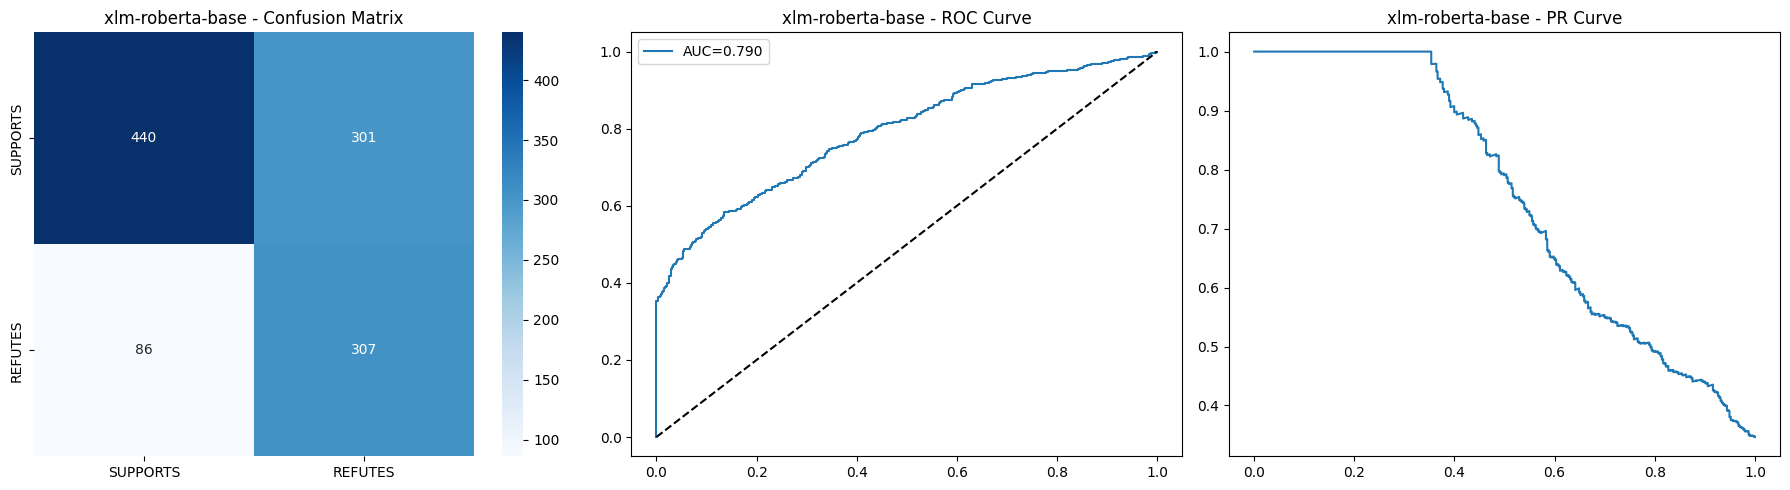

              precision    recall  f1-score   support

    SUPPORTS       0.84      0.59      0.69       741
     REFUTES       0.50      0.78      0.61       393

    accuracy                           0.66      1134
   macro avg       0.67      0.69      0.65      1134
weighted avg       0.72      0.66      0.67      1134

[xlm-roberta-base] GPU allocated: 4.61 GB | reserved: 5.61 GB

=== muril ===
attempt 1/3: lr=2e-05


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at google/muril-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  0%|          | 0/1420 [00:00<?, ?it/s]

{'loss': 0.2014, 'grad_norm': 0.1193927600979805, 'learning_rate': 1.418439716312057e-06, 'epoch': 0.04}
{'loss': 0.2035, 'grad_norm': 0.21083734929561615, 'learning_rate': 2.836879432624114e-06, 'epoch': 0.07}
{'loss': 0.1937, 'grad_norm': 0.11606542021036148, 'learning_rate': 4.255319148936171e-06, 'epoch': 0.11}
{'loss': 0.198, 'grad_norm': 0.04319575056433678, 'learning_rate': 5.673758865248228e-06, 'epoch': 0.14}
{'loss': 0.2122, 'grad_norm': 0.3768898844718933, 'learning_rate': 7.092198581560285e-06, 'epoch': 0.18}
{'loss': 0.2002, 'grad_norm': 0.09331104904413223, 'learning_rate': 8.510638297872341e-06, 'epoch': 0.21}
{'loss': 0.1859, 'grad_norm': 0.07448577880859375, 'learning_rate': 9.929078014184398e-06, 'epoch': 0.25}
{'loss': 0.1822, 'grad_norm': 0.15871889889240265, 'learning_rate': 1.1347517730496456e-05, 'epoch': 0.28}
{'loss': 0.1882, 'grad_norm': 0.1318434476852417, 'learning_rate': 1.2765957446808513e-05, 'epoch': 0.32}
{'loss': 0.1779, 'grad_norm': 0.2375149875879287

  0%|          | 0/36 [00:00<?, ?it/s]

{'eval_loss': 0.18643541634082794, 'eval_accuracy': 0.34656084656084657, 'eval_macro_f1': 0.25736738703339884, 'eval_runtime': 17.6359, 'eval_samples_per_second': 64.301, 'eval_steps_per_second': 2.041, 'epoch': 1.0}
{'loss': 0.1918, 'grad_norm': 0.17117558419704437, 'learning_rate': 1.9337710161901322e-05, 'epoch': 1.02}
{'loss': 0.183, 'grad_norm': 0.18149340152740479, 'learning_rate': 1.9246998812587748e-05, 'epoch': 1.06}
{'loss': 0.1822, 'grad_norm': 0.1626843363046646, 'learning_rate': 1.9150708703988064e-05, 'epoch': 1.09}
{'loss': 0.191, 'grad_norm': 0.07918646186590195, 'learning_rate': 1.9048897928392357e-05, 'epoch': 1.13}
{'loss': 0.1818, 'grad_norm': 0.14543907344341278, 'learning_rate': 1.894162790873593e-05, 'epoch': 1.16}
{'loss': 0.1835, 'grad_norm': 0.1308290958404541, 'learning_rate': 1.882896336154253e-05, 'epoch': 1.2}
{'loss': 0.1832, 'grad_norm': 0.0474831759929657, 'learning_rate': 1.8710972257880568e-05, 'epoch': 1.23}
{'loss': 0.1806, 'grad_norm': 0.3159381449

... (45 outputs left out)

  0%|          | 0/36 [00:00<?, ?it/s]

{'eval_loss': 0.1850629299879074, 'eval_accuracy': 0.8209876543209876, 'eval_macro_f1': 0.8036467480448009, 'eval_runtime': 16.2707, 'eval_samples_per_second': 69.696, 'eval_steps_per_second': 2.213, 'epoch': 5.0}
{'train_runtime': 1570.2648, 'train_samples_per_second': 14.443, 'train_steps_per_second': 0.904, 'train_loss': 0.10914849945357148, 'epoch': 5.0}


  0%|          | 0/36 [00:00<?, ?it/s]

  0%|          | 0/36 [00:00<?, ?it/s]

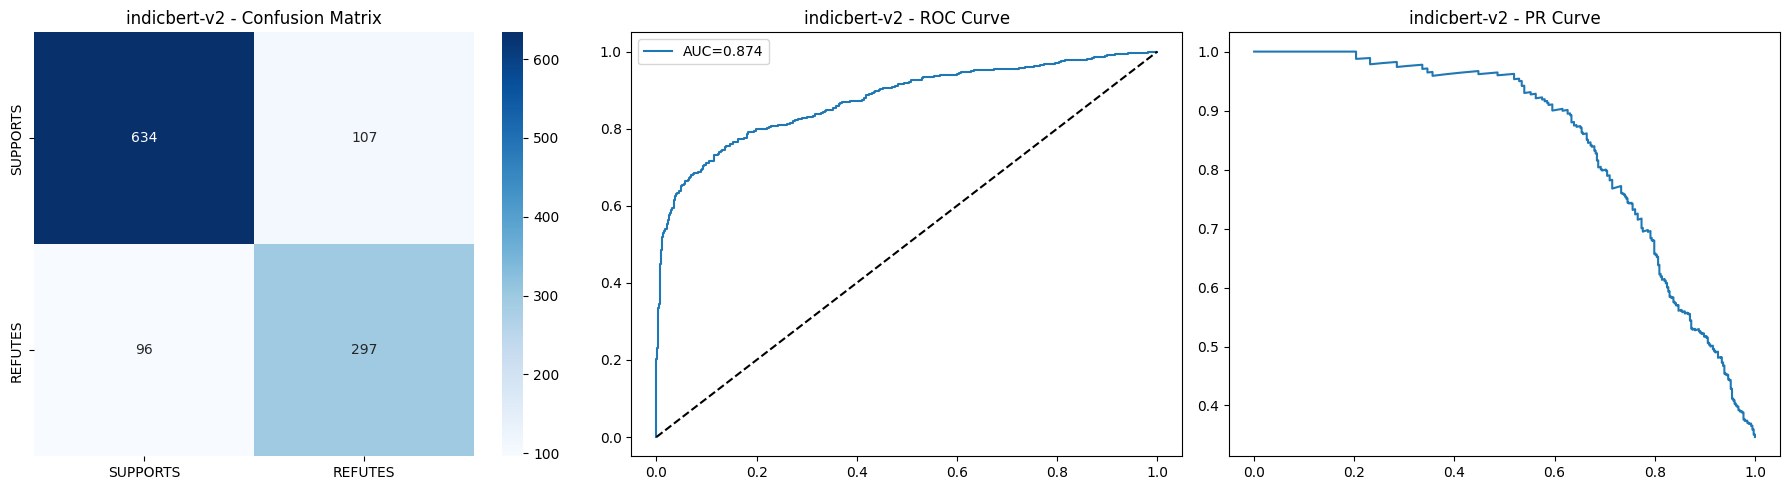

              precision    recall  f1-score   support

    SUPPORTS       0.87      0.86      0.86       741
     REFUTES       0.74      0.76      0.75       393

    accuracy                           0.82      1134
   macro avg       0.80      0.81      0.80      1134
weighted avg       0.82      0.82      0.82      1134

[indicbert-v2] GPU allocated: 4.62 GB | reserved: 5.61 GB
Usable models: ['xlm-roberta-base', 'indicbert-v2']


In [26]:
model_results = {}
for model_key, config in MODEL_CONFIGS.items():
    result = train_and_evaluate_model(model_key, config, train_claims, train_evidences, train_labels,
                                       dev_claims, dev_evidences, dev_labels)
    if result is not None:
        model_results[model_key] = result
    cleanup()

print(f"Usable models: {list(model_results.keys())}")

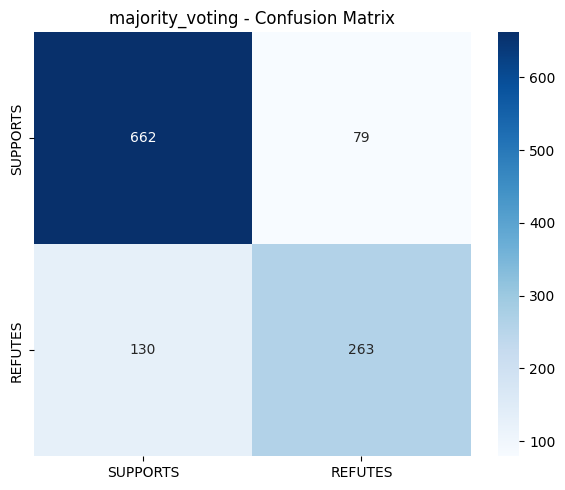

              precision    recall  f1-score   support

    SUPPORTS       0.84      0.89      0.86       741
     REFUTES       0.77      0.67      0.72       393

    accuracy                           0.82      1134
   macro avg       0.80      0.78      0.79      1134
weighted avg       0.81      0.82      0.81      1134



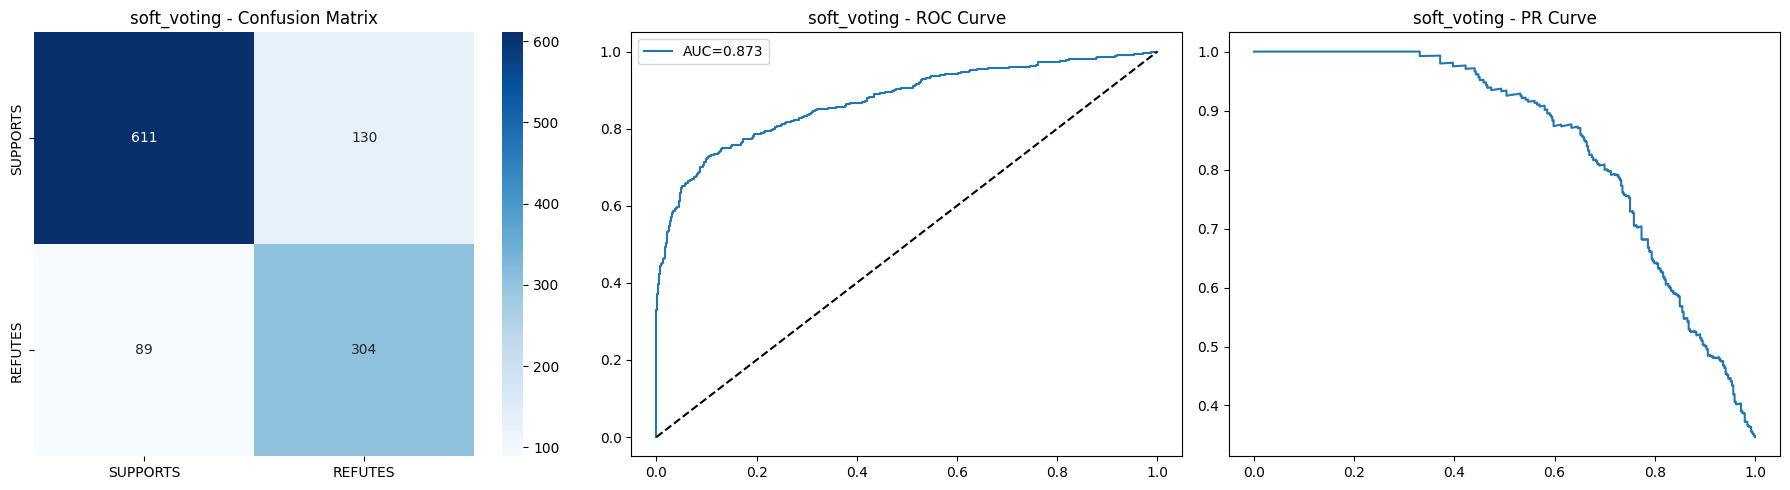

              precision    recall  f1-score   support

    SUPPORTS       0.87      0.82      0.85       741
     REFUTES       0.70      0.77      0.74       393

    accuracy                           0.81      1134
   macro avg       0.79      0.80      0.79      1134
weighted avg       0.81      0.81      0.81      1134



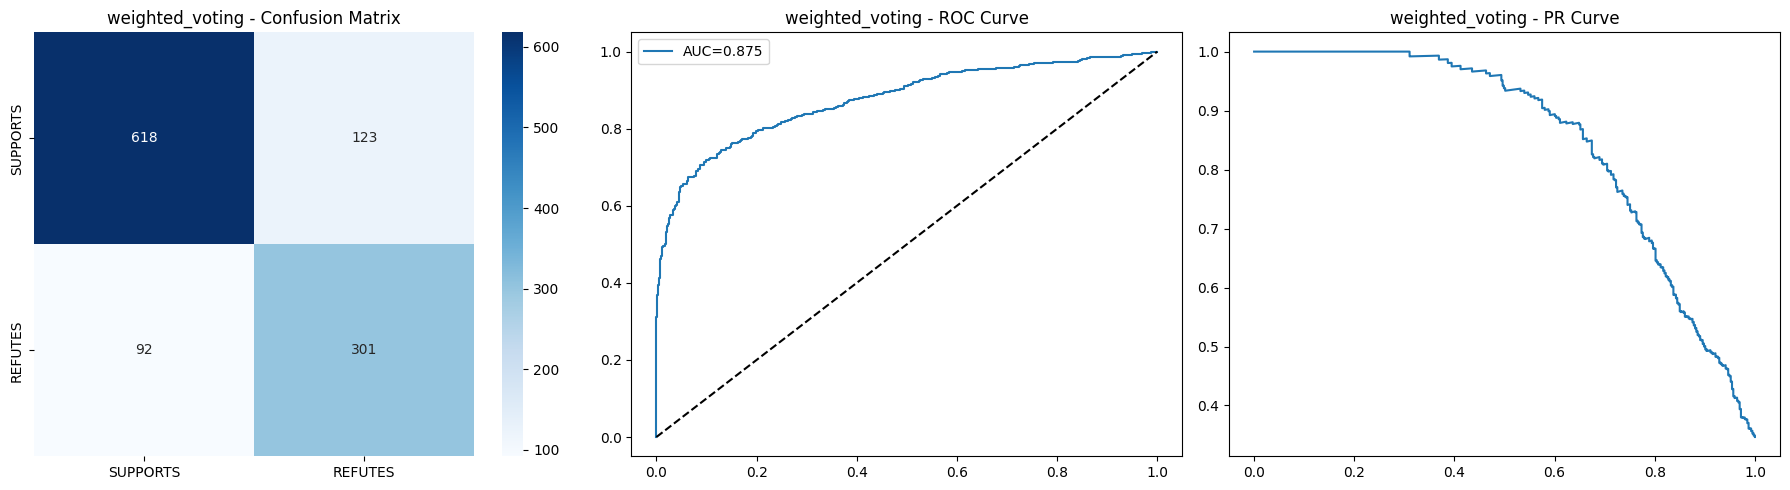

              precision    recall  f1-score   support

    SUPPORTS       0.87      0.83      0.85       741
     REFUTES       0.71      0.77      0.74       393

    accuracy                           0.81      1134
   macro avg       0.79      0.80      0.79      1134
weighted avg       0.81      0.81      0.81      1134



In [27]:
def majority_voting(pred_list):
    stacked = np.stack(pred_list, axis=1)
    return np.array([np.bincount(row, minlength=2).argmax() for row in stacked])

def soft_voting(prob_list):
    avg_probs = np.mean(np.stack(prob_list, axis=0), axis=0)
    return np.argmax(avg_probs, axis=1), avg_probs[:, 1]

def weighted_voting(prob_list, weights):
    weights = np.array(weights) / sum(weights)
    weighted_probs = sum(w * p for w, p in zip(weights, prob_list))
    return np.argmax(weighted_probs, axis=1), weighted_probs[:, 1]

ensemble_results = {}
usable_keys = [k for k, r in model_results.items() if not is_degenerate_model(dev_labels, r["dev_pred"])]

if len(usable_keys) >= 2:
    pred_list = [model_results[k]["dev_pred"] for k in usable_keys]
    prob_list = [model_results[k]["dev_probs"] for k in usable_keys]
    macro_f1_list = [model_results[k]["metrics"]["macro_f1"] ** 2 for k in usable_keys]

    maj_pred = majority_voting(pred_list)
    ensemble_results["majority_voting"] = {"dev_pred": maj_pred, "metrics": compute_classification_metrics(dev_labels, maj_pred)}

    soft_pred, soft_prob = soft_voting(prob_list)
    ensemble_results["soft_voting"] = {"dev_pred": soft_pred, "metrics": compute_classification_metrics(dev_labels, soft_pred, soft_prob)}

    weighted_pred, weighted_prob = weighted_voting(prob_list, macro_f1_list)
    ensemble_results["weighted_voting"] = {"dev_pred": weighted_pred, "metrics": compute_classification_metrics(dev_labels, weighted_pred, weighted_prob)}

    for name, res in ensemble_results.items():
        prob_arg = weighted_prob if name == "weighted_voting" else (soft_prob if name == "soft_voting" else None)
        plot_confusion_and_curves(dev_labels, res["dev_pred"], prob_arg, name)

In [28]:
comparison_rows = [{"approach": k, "type": "individual", **model_results[k]["metrics"]} for k in usable_keys]
comparison_rows += [{"approach": k, "type": "ensemble", **r["metrics"]} for k, r in ensemble_results.items()]

comparison_df = pd.DataFrame(comparison_rows).set_index("approach")
comparison_df["success@3"] = final_retrieval_metrics.get("success@k")
comparison_df["ndcg@3"] = final_retrieval_metrics.get("ndcg@k")
comparison_df = comparison_df.sort_values("macro_f1", ascending=False)
display(comparison_df)

top_approaches = comparison_df.head(TOP_N_APPROACHES).index.tolist()
print(f"\nTop {TOP_N_APPROACHES} approaches selected for full submission generation: {top_approaches}")

,type,accuracy,precision,recall,macro_precision,macro_recall,macro_f1,weighted_f1,f1_class_SUPPORTS,f1_class_REFUTES,success@3,ndcg@3
approach,,,,,,,,,,,,
indicbert-v2,individual,0.820988,0.735149,0.755725,0.801821,0.805663,0.803647,0.821554,0.861999,0.745295,0.48,0.335949
weighted_voting,ensemble,0.810406,0.709906,0.765903,0.790164,0.799956,0.794334,0.811977,0.851826,0.736842,0.48,0.335949
soft_voting,ensemble,0.806878,0.700461,0.773537,0.786659,0.799049,0.791605,0.808918,0.848022,0.735187,0.48,0.335949
majority_voting,ensemble,0.815697,0.769006,0.669211,0.802432,0.781299,0.789656,0.812368,0.863666,0.715646,0.48,0.335949
xlm-roberta-base,individual,0.658730,0.504934,0.781170,0.670718,0.687481,0.653970,0.666425,0.694554,0.613387,0.48,0.335949



Top 3 approaches selected for full submission generation: ['indicbert-v2', 'weighted_voting', 'soft_voting']


In [29]:
metrics_df = pd.DataFrame([{"model": k, **r["metrics"]} for k, r in model_results.items()]).set_index("model")
display(metrics_df)

,accuracy,precision,recall,macro_precision,macro_recall,macro_f1,weighted_f1,f1_class_SUPPORTS,f1_class_REFUTES
model,,,,,,,,,
xlm-roberta-base,0.658730,0.504934,0.781170,0.670718,0.687481,0.653970,0.666425,0.694554,0.613387
indicbert-v2,0.820988,0.735149,0.755725,0.801821,0.805663,0.803647,0.821554,0.861999,0.745295


In [30]:
def validate_submission(records: List[dict], subtask: int) -> Tuple[bool, List[str]]:
    errors, seen_ids = [], set()
    for i, r in enumerate(records):
        rid = r.get("ID")
        if rid is None or rid == "":
            errors.append(f"Record {i}: missing ID")
        elif rid in seen_ids:
            errors.append(f"Record {i}: duplicate ID {rid}")
        else:
            seen_ids.add(rid)

        if subtask == 1:
            ev = r.get("top_3_evidence", [])
            if len(ev) != 3:
                errors.append(f"Record {i}: expected 3 evidences, got {len(ev)}")
            if any(not e or not str(e).strip() for e in ev):
                errors.append(f"Record {i}: empty evidence")
            if r.get("Prediction") not in {"SUPPORTS", "REFUTES"}:
                errors.append(f"Record {i}: invalid label {r.get('Prediction')}")

        if subtask == 2:
            if not r.get("Evidence", "").strip():
                errors.append(f"Record {i}: empty Evidence")
            if not r.get("Justification", "").strip():
                errors.append(f"Record {i}: empty Justification")
            if r.get("Prediction") not in {"SUPPORTS", "REFUTES"}:
                errors.append(f"Record {i}: invalid label {r.get('Prediction')}")

    try:
        json.dumps(records, ensure_ascii=False)
    except (TypeError, UnicodeError) as e:
        errors.append(f"Serialization error: {e}")

    return len(errors) == 0, errors

In [31]:
def get_test_text_col(df): return next((c for c in ["Text", "claim", "Claim", "text"] if c in df.columns), df.columns[0])
def get_test_id_col(df): return next((c for c in ["ID", "id", "Id"] if c in df.columns), None)

if TEST_POOL_IS_DEDICATED:
    evidence_pool = evidence_pool_test
    pool_source = "evidence_pool_test.json"
else:
    pool_source = "train pool (fallback)"

evidence_pool.id2text = {k: clean_text(v) for k, v in evidence_pool.id2text.items()}
evidence_pool.texts = [evidence_pool.id2text[i] for i in evidence_pool.ids]
print(f"Test evidence pool source: {pool_source} | size: {len(evidence_pool.ids)}")

best_dense_model = load_with_retry(SentenceTransformer, best_embedding_model_name, device=str(device))
best_ev_emb = best_dense_model.encode(evidence_pool.texts, convert_to_numpy=True, batch_size=64, show_progress_bar=True)
best_index = build_faiss_index(best_ev_emb)

bm25_corpus = [tokenize_simple(t) for t in evidence_pool.texts]
bm25 = BM25Okapi(bm25_corpus)
tfidf_vectorizer = TfidfVectorizer(max_features=50000, ngram_range=(1, 2)).fit(evidence_pool.texts)
tfidf_matrix = tfidf_vectorizer.transform(evidence_pool.texts)
reranker = load_with_retry(CrossEncoder, RERANKER_MODEL, device=str(device))

Test evidence pool source: evidence_pool_test.json | size: 28618


'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: 81f70576-5ede-4318-a4ab-3a6ed60c56a4)')' thrown while requesting HEAD https://huggingface.co/intfloat/multilingual-e5-base/resolve/main/modules.json
Retrying in 1s [Retry 1/5].


Batches:   0%|          | 0/448 [00:00<?, ?it/s]

In [32]:
def predict_probs_for_model(model_key: str, claims: List[str], evidences: List[List[str]]) -> np.ndarray:
    config = MODEL_CONFIGS[model_key]
    tokenizer, model = load_tokenizer_and_model_with_retry(config["name"])
    model = model.to(device)
    model.eval()
    ds = VeracityDataset(claims, evidences, None, tokenizer, config["max_len"])
    loader = DataLoader(ds, batch_size=32)
    all_probs = []
    with torch.no_grad():
        for batch in tqdm(loader, desc=f"Inference [{model_key}]"):
            batch = {k: v.to(device) for k, v in batch.items()}
            logits = model(**batch).logits
            all_probs.append(torch.softmax(logits, dim=1).cpu().numpy())
    probs = np.concatenate(all_probs, axis=0)
    cleanup(model, tokenizer, ds, loader)
    return probs

def predict_with_approach(approach: str, claims: List[str], evidences: List[List[str]]) -> np.ndarray:
    if approach in model_results:
        probs = predict_probs_for_model(approach, claims, evidences)
        return np.argmax(probs, axis=1)

    all_model_probs = [predict_probs_for_model(k, claims, evidences) for k in usable_keys]
    macro_f1_list = [model_results[k]["metrics"]["macro_f1"] ** 2 for k in usable_keys]

    if approach == "majority_voting":
        return majority_voting([np.argmax(p, axis=1) for p in all_model_probs])
    elif approach == "soft_voting":
        pred, _ = soft_voting(all_model_probs)
        return pred
    else:
        pred, _ = weighted_voting(all_model_probs, macro_f1_list)
        return pred

In [33]:
retrieved_by_lang = {}
for lang, records in test_a_raw.items():
    if not records:
        retrieved_by_lang[lang] = None
        continue
    df = to_df(records)
    text_col, id_col = get_test_text_col(df), get_test_id_col(df)
    df = preprocess_dataframe(df, [text_col], id_col=id_col)

    retrieved_all, evidence_texts_all = [], []
    for claim in tqdm(df[text_col].tolist(), desc=f"Retrieval [{lang}]"):
        top3 = full_retrieval_pipeline(claim, top_n=3, use_mmr=True)
        while len(top3) < 3 and evidence_pool.ids:
            top3.append(top3[-1] if top3 else evidence_pool.ids[0])
        retrieved_all.append(top3)
        evidence_texts_all.append([evidence_pool.get(e) for e in top3])

    retrieved_by_lang[lang] = {"df": df, "text_col": text_col, "id_col": id_col, "evidence_texts": evidence_texts_all}

cleanup(best_dense_model, best_ev_emb, best_index, reranker)

Retrieval [english]:   0%|          | 0/1200 [00:00<?, ?it/s]

Retrieval [hindi]:   0%|          | 0/1200 [00:00<?, ?it/s]

Retrieval [bengali]:   0%|          | 0/1200 [00:00<?, ?it/s]

Retrieval [codemix]:   0%|          | 0/300 [00:00<?, ?it/s]

In [34]:
OUTPUT_DIR = f"{DATA_ROOT}/submissions"

for approach in top_approaches:
    approach_dir = f"{OUTPUT_DIR}/{approach}"
    os.makedirs(approach_dir, exist_ok=True)
    print(f"\n=== Generating Subtask 1 submissions for approach: {approach} ===")

    for lang, data in retrieved_by_lang.items():
        if data is None:
            continue
        df, evidence_texts_all = data["df"], data["evidence_texts"]
        preds = predict_with_approach(approach, df[data["text_col"]].tolist(), evidence_texts_all)

        output = []
        for i in range(len(df)):
            row_id = str(df.iloc[i][data["id_col"]]) if data["id_col"] else f"{lang}_{i}"
            output.append({"ID": row_id, "top_3_evidence": evidence_texts_all[i][:3], "Prediction": ID2LABEL[int(preds[i])]})

        ok, errors = validate_submission(output, subtask=1)
        print(f"  [{approach}] {lang}: {'VALID' if ok else 'INVALID'} ({len(errors)} issues), {len(output)} records")

        fname = f"{approach_dir}/{LANG_LABEL[lang]}_subtask1.json"
        with open(fname, "w", encoding="utf-8") as f:
            json.dump(output, f, ensure_ascii=False, indent=2)


=== Generating Subtask 1 submissions for approach: indicbert-v2 ===


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-only and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Inference [indicbert-v2]:   0%|          | 0/38 [00:00<?, ?it/s]

  [indicbert-v2] english: VALID (0 issues), 1200 records


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-only and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Inference [indicbert-v2]:   0%|          | 0/38 [00:00<?, ?it/s]

... (43 outputs left out)

Inference [xlm-roberta-base]:   0%|          | 0/10 [00:00<?, ?it/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-only and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Inference [indicbert-v2]:   0%|          | 0/10 [00:00<?, ?it/s]

  [soft_voting] codemix: VALID (0 issues), 300 records


In [35]:
best_dense_model = load_with_retry(SentenceTransformer, best_embedding_model_name, device=str(device))
best_ev_emb = best_dense_model.encode(evidence_pool.texts, convert_to_numpy=True, batch_size=64, show_progress_bar=True)
best_index = build_faiss_index(best_ev_emb)
reranker = load_with_retry(CrossEncoder, RERANKER_MODEL, device=str(device))

try:
    generator_tokenizer = load_with_retry(AutoTokenizer.from_pretrained, RAG_GENERATOR_MODEL)
    gen_pipeline = hf_pipeline("text2text-generation", model=RAG_GENERATOR_MODEL,
                                tokenizer=generator_tokenizer, device=0 if torch.cuda.is_available() else -1)
except Exception as e:
    print(f"Generator load failed, using extractive fallback: {e}")
    gen_pipeline = None

def open_domain_retrieve(claim, k=5): return full_retrieval_pipeline(claim, top_n=k)

def extractive_fallback_summary(evidence_texts, max_words=150):
    return " ".join(" ".join(evidence_texts).split()[:max_words])

def build_summary_prompt(claim, evidence_texts):
    context = "\n".join(f"- {e}" for e in evidence_texts)
    return (f"Summarize the following evidence strictly using only the given facts. "
            f"Keep it 100 to 150 words.\n\nClaim: {claim}\nEvidence:\n{context}\n\nSummary:")

def build_justification_prompt(claim, summary, label):
    return (f"Claim: {claim}\nEvidence summary: {summary}\nLabel: {label}\n"
            "Write a justification of 100 to 120 words based only on the summary above.")

def generate_text(prompt, max_new_tokens=180):
    if gen_pipeline is None:
        return prompt.split("Evidence:")[-1][:600] if "Evidence:" in prompt else prompt[:600]
    return gen_pipeline(prompt, max_new_tokens=max_new_tokens, do_sample=False)[0]["generated_text"].strip()

def verify_label(claim, summary):
    claim_tokens = set(tokenize_simple(claim))
    summary_tokens = set(tokenize_simple(summary))
    overlap = len(claim_tokens & summary_tokens) / max(1, len(claim_tokens))
    negation_words = {"not", "no", "never", "false", "denied", "नहीं", "না"}
    # Subtask 2 uses SUPPORTS/REFUTES, same as Subtask 1 -- not SUPPORTED/REFUTED
    return "REFUTES" if (bool(negation_words & summary_tokens) or overlap < 0.2) else "SUPPORTS"

def rag_pipeline(claim: str) -> dict:
    top_evidence_ids = open_domain_retrieve(claim, k=5)
    evidence_texts = [evidence_pool.get(e) for e in top_evidence_ids] if top_evidence_ids else ["No evidence retrieved."]
    summary_prompt = build_summary_prompt(claim, evidence_texts)
    summary = generate_text(summary_prompt) if gen_pipeline else extractive_fallback_summary(evidence_texts)
    label = verify_label(claim, summary)
    just_prompt = build_justification_prompt(claim, summary, label)
    justification = generate_text(just_prompt, max_new_tokens=150) if gen_pipeline else extractive_fallback_summary([summary], max_words=120)
    # field names must match the schema exactly: Evidence, Justification (capitalized)
    return {"Evidence": summary, "Prediction": label, "Justification": justification}

Batches:   0%|          | 0/448 [00:00<?, ?it/s]

You are using the default legacy behaviour of the <class 'transformers.models.t5.tokenization_t5.T5Tokenizer'>. This is expected, and simply means that the `legacy` (previous) behavior will be used so nothing changes for you. If you want to use the new behaviour, set `legacy=False`. This should only be set if you understand what it means, and thoroughly read the reason why this was added as explained in https://github.com/huggingface/transformers/pull/24565


In [36]:
def generate_subtask2_submission(lang: str, records) -> List[dict]:
    if not records:
        return []
    df = to_df(records)
    text_col, id_col = get_test_text_col(df), get_test_id_col(df)
    df = preprocess_dataframe(df, [text_col], id_col=id_col)

    output = []
    for i, row in tqdm(df.iterrows(), total=len(df), desc=f"RAG [{lang}]"):
        row_id = str(row[id_col]) if id_col else f"{lang}_{i}"
        try:
            result = rag_pipeline(row[text_col])
        except Exception:
            result = {"evidence_summary": "Evidence unavailable due to processing error.",
                      "justification": "Unable to generate justification.", "Prediction": "REFUTED"}
        output.append({"ID": row_id, **result})
    return output

os.makedirs(f"{OUTPUT_DIR}/subtask2_shared", exist_ok=True)
subtask2_outputs = {}
for lang, records in test_b_raw.items():
    output = generate_subtask2_submission(lang, records)
    subtask2_outputs[lang] = output
    ok, errors = validate_submission(output, subtask=2)
    print(f"Subtask2 [{lang}]: {'VALID' if ok else 'INVALID'} ({len(errors)} issues)")
    fname = f"{OUTPUT_DIR}/subtask2_shared/{LANG_LABEL[lang]}_subtask2.json"
    with open(fname, "w", encoding="utf-8") as f:
        json.dump(output, f, ensure_ascii=False, indent=2)

cleanup(gen_pipeline, best_dense_model, best_ev_emb, best_index, reranker)

RAG [english]:   0%|          | 0/299 [00:00<?, ?it/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Subtask2 [english]: VALID (0 issues)


RAG [hindi]:   0%|          | 0/278 [00:00<?, ?it/s]

Subtask2 [hindi]: VALID (0 issues)


RAG [bengali]:   0%|          | 0/258 [00:00<?, ?it/s]

Subtask2 [bengali]: VALID (0 issues)


RAG [codemix]:   0%|          | 0/174 [00:00<?, ?it/s]

Subtask2 [codemix]: VALID (0 issues)


In [37]:
print("=== Submission files generated ===\n")
for approach in top_approaches:
    approach_dir = f"{OUTPUT_DIR}/{approach}"
    print(f"Approach: {approach}")
    for f in sorted(os.listdir(approach_dir)):
        full_path = os.path.join(approach_dir, f)
        print(f"  {full_path} ({os.path.getsize(full_path)/1024:.1f} KB)")
    print()

print("Subtask 2 (shared across approaches, one file per language):")
for f in sorted(os.listdir(f"{OUTPUT_DIR}/subtask2_shared")):
    full_path = os.path.join(f"{OUTPUT_DIR}/subtask2_shared", f)
    print(f"  {full_path} ({os.path.getsize(full_path)/1024:.1f} KB)")

cleanup()

=== Submission files generated ===

Approach: indicbert-v2
  C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/submissions/indicbert-v2\Bengali_subtask1.json (4279.6 KB)
  C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/submissions/indicbert-v2\CodeMix_subtask1.json (605.7 KB)
  C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/submissions/indicbert-v2\English_subtask1.json (2598.8 KB)
  C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/submissions/indicbert-v2\Hindi_subtask1.json (5427.3 KB)

Approach: weighted_voting
  C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/submissions/weighted_voting\Bengali_subtask1.json (4279.9 KB)
  C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/submissions/weighted_voting\CodeMix_subtask1.json (606.0 KB)
  C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/submissions/weighted_voting\English_subtask1.json (2598.8 KB)
  C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/submissions/weighted_voting\Hindi_subtask1.json (5428.4 KB)

Approach: soft_voting
  C:/Users/VGST/Desktop/FIRE-

In [38]:
runs_df = comparison_df.head(TOP_N_APPROACHES)[
    ["type", "accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1",
     "f1_class_SUPPORTS", "f1_class_REFUTES", "success@3", "ndcg@3"]
].copy().round(4)
runs_df.insert(0, "run", range(1, len(runs_df) + 1))
runs_df.insert(1, "submission_folder", [f"{OUTPUT_DIR}/{a}" for a in runs_df.index])
display(runs_df)

selection_df = pd.DataFrame({
    "run": range(1, len(top_approaches) + 1),
    "approach": top_approaches,
    "selection_criterion": "dev macro_f1 rank",
    "models_used": [a if a in model_results else " + ".join(usable_keys) for a in top_approaches],
})
display(selection_df)

,run,submission_folder,type,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,f1_class_SUPPORTS,f1_class_REFUTES,success@3,ndcg@3
approach,,,,,,,,,,,,
indicbert-v2,1,C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/...,individual,0.8210,0.8018,0.8057,0.8036,0.8216,0.8620,0.7453,0.48,0.3359
weighted_voting,2,C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/...,ensemble,0.8104,0.7902,0.8000,0.7943,0.8120,0.8518,0.7368,0.48,0.3359
soft_voting,3,C:/Users/VGST/Desktop/FIRE-2026/IndicClaimVer/...,ensemble,0.8069,0.7867,0.7990,0.7916,0.8089,0.8480,0.7352,0.48,0.3359


,run,approach,selection_criterion,models_used
0,1,indicbert-v2,dev macro_f1 rank,indicbert-v2
1,2,weighted_voting,dev macro_f1 rank,xlm-roberta-base + indicbert-v2
2,3,soft_voting,dev macro_f1 rank,xlm-roberta-base + indicbert-v2


In [39]:
AB_N_CLAIMS = 300
AB_K = 30
AB_RUN_TRAINING = True
AB_EPOCHS = 3

ab_pool = load_evidence_pool_robust(PATHS["evidence_pool"])
if len(ab_pool.ids) < MIN_POOL_SIZE:
    ab_pool = build_pool_from_gold_evidence(train_df, dev_df, text_col=COL_EVIDENCE)
ab_pool.id2text = {k: clean_text(v) for k, v in ab_pool.id2text.items()}
ab_pool.texts = [ab_pool.id2text[i] for i in ab_pool.ids]
ab_text2id = {v: k for k, v in ab_pool.id2text.items()}
ab_id2idx = {eid: i for i, eid in enumerate(ab_pool.ids)}

ab_dev = dev_df.copy()
ab_dev["ab_rel"] = ab_dev[COL_EVIDENCE].apply(lambda t: [ab_text2id[t]] if t in ab_text2id else [])
ab_dev = ab_dev[ab_dev["ab_rel"].apply(len) > 0].head(AB_N_CLAIMS).reset_index(drop=True)
ab_claims = ab_dev[COL_CLAIM].tolist()
ab_relevant = ab_dev["ab_rel"].tolist()
print(f"Pool: {len(ab_pool.ids)} | ablation claims: {len(ab_claims)}")

ab_dense = load_with_retry(SentenceTransformer, best_embedding_model_name, device=str(device))
ab_emb = ab_dense.encode(ab_pool.texts, convert_to_numpy=True, batch_size=64, show_progress_bar=True)
ab_index = build_faiss_index(ab_emb)
ab_reranker = load_with_retry(CrossEncoder, RERANKER_MODEL, device=str(device))

ab_bm25 = BM25Okapi([tokenize_simple(t) for t in ab_pool.texts])
ab_tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2))
ab_tfidf_matrix = ab_tfidf.fit_transform(ab_pool.texts)

q_emb = ab_dense.encode(ab_claims, convert_to_numpy=True, batch_size=64, show_progress_bar=False)
faiss.normalize_L2(q_emb)
d_scores, d_idx = ab_index.search(q_emb, AB_K)

ab_cache = []
for i, claim in enumerate(tqdm(ab_claims, desc="Caching candidates")):
    b = ab_bm25.get_scores(tokenize_simple(claim))
    b_top = np.argsort(b)[::-1][:AB_K]
    t = (ab_tfidf_matrix @ ab_tfidf.transform([claim]).T).toarray().ravel()
    t_top = np.argsort(t)[::-1][:AB_K]
    ab_cache.append({
        "dense": [(ab_pool.ids[j], float(s)) for j, s in zip(d_idx[i], d_scores[i])],
        "bm25": [(ab_pool.ids[j], float(b[j])) for j in b_top],
        "tfidf": [(ab_pool.ids[j], float(t[j])) for j in t_top],
    })

Pool: 13333 | ablation claims: 300


Batches:   0%|          | 0/209 [00:00<?, ?it/s]

Caching candidates:   0%|          | 0/300 [00:00<?, ?it/s]

In [40]:
ab_ce_cache = {}

def ab_ce_scores(i, cand_ids):
    missing = [e for e in cand_ids if (i, e) not in ab_ce_cache]
    if missing:
        preds = ab_reranker.predict([(ab_claims[i], ab_pool.get(e)) for e in missing], show_progress_bar=False)
        for e, s in zip(missing, preds):
            ab_ce_cache[(i, e)] = float(s)
    return {e: ab_ce_cache[(i, e)] for e in cand_ids}

def ab_weighted(dense, sparse, alpha):
    ds, ss = dict(dense), dict(sparse)
    ids = list(set(ds) | set(ss))
    dv = minmax_norm([ds.get(e, 0.0) for e in ids])
    sv = minmax_norm([ss.get(e, 0.0) for e in ids])
    fused = {e: alpha * d + (1 - alpha) * s for e, d, s in zip(ids, dv, sv)}
    return [e for e, _ in sorted(fused.items(), key=lambda x: x[1], reverse=True)]

def ab_rrf(dense, sparse, rrf_k=60):
    dr = {e: r for r, (e, _) in enumerate(dense)}
    sr = {e: r for r, (e, _) in enumerate(sparse)}
    ids = set(dr) | set(sr)
    sc = {e: 1 / (rrf_k + dr.get(e, AB_K + 1)) + 1 / (rrf_k + sr.get(e, AB_K + 1)) for e in ids}
    return [e for e, _ in sorted(sc.items(), key=lambda x: x[1], reverse=True)]

def ab_dedup(cand_ids, threshold=0.85):
    kept, kept_txt = [], []
    for e in cand_ids:
        t = ab_pool.get(e)
        if any(SequenceMatcher(None, t, k).ratio() > threshold for k in kept_txt):
            continue
        kept.append(e)
        kept_txt.append(t)
    return kept

def ab_mmr(cand_ids, rel, top_n=3, lam=0.6):
    emb = ab_emb[[ab_id2idx[e] for e in cand_ids]]
    sel, remaining = [], list(range(len(cand_ids)))
    while len(sel) < top_n and remaining:
        best_i, best_s = None, -1e9
        for i in remaining:
            sim = max((float(emb[i] @ emb[j]) for j in sel), default=0.0)
            s = lam * rel[cand_ids[i]] - (1 - lam) * sim
            if s > best_s:
                best_i, best_s = i, s
        sel.append(best_i)
        remaining.remove(best_i)
    return [cand_ids[i] for i in sel]

def ab_pipeline(i, fusion="rrf", dedup=False, rerank=False, mmr=False, alpha=0.5, top_n=3):
    c = ab_cache[i]
    if fusion in ("bm25", "tfidf", "dense"):
        cands = [e for e, _ in c[fusion]]
    elif fusion == "weighted":
        cands = ab_weighted(c["dense"], c["bm25"], alpha)
    else:
        cands = ab_rrf(c["dense"], c["bm25"])
    if dedup:
        cands = ab_dedup(cands)
    if rerank:
        sc = ab_ce_scores(i, cands)
        cands = sorted(cands, key=lambda e: sc[e], reverse=True)[:15]
        if mmr and len(cands) > top_n:
            return ab_mmr(cands, sc, top_n)
    return cands[:top_n]

def ab_eval(**kw):
    retrieved = [ab_pipeline(i, **kw) for i in range(len(ab_claims))]
    return evaluate_retrieval(retrieved, ab_relevant, k=3)

In [41]:
fusion_main = best_fusion_strategy if best_fusion_strategy in ("rrf", "weighted") else "rrf"
alpha_main = best_alpha

configs = {
    "BM25 only": dict(fusion="bm25"),
    "TF-IDF only": dict(fusion="tfidf"),
    "Dense only": dict(fusion="dense"),
    "Hybrid (weighted)": dict(fusion="weighted", alpha=alpha_main),
    "Hybrid (RRF)": dict(fusion="rrf"),
    f"Hybrid ({fusion_main}) + dedup": dict(fusion=fusion_main, alpha=alpha_main, dedup=True),
    f"Hybrid ({fusion_main}) + rerank": dict(fusion=fusion_main, alpha=alpha_main, rerank=True),
    f"Hybrid ({fusion_main}) + dedup + rerank": dict(fusion=fusion_main, alpha=alpha_main, dedup=True, rerank=True),
    "FULL (dedup + rerank + MMR)": dict(fusion=fusion_main, alpha=alpha_main, dedup=True, rerank=True, mmr=True),
    "FULL - dedup": dict(fusion=fusion_main, alpha=alpha_main, dedup=False, rerank=True, mmr=True),
    "FULL - rerank": dict(fusion=fusion_main, alpha=alpha_main, dedup=True, rerank=False, mmr=False),
    "FULL - MMR": dict(fusion=fusion_main, alpha=alpha_main, dedup=True, rerank=True, mmr=False),
    "FULL - hybrid (dense only)": dict(fusion="dense", dedup=True, rerank=True, mmr=True),
    "FULL - hybrid (BM25 only)": dict(fusion="bm25", dedup=True, rerank=True, mmr=True),
}

rows = []
for name, kw in tqdm(configs.items(), desc="Retrieval ablation"):
    m = ab_eval(**kw)
    rows.append({"Configuration": name, **{k: round(v, 4) for k, v in m.items()}})

retrieval_ablation_df = pd.DataFrame(rows).set_index("Configuration")
display(retrieval_ablation_df)

Retrieval ablation:   0%|          | 0/14 [00:00<?, ?it/s]

,success@k,ndcg@k,precision@k,recall@k,mrr,map
Configuration,,,,,,
BM25 only,0.7633,0.5698,0.2544,0.7633,0.5039,0.5039
TF-IDF only,0.6933,0.5394,0.2311,0.6933,0.4867,0.4867
Dense only,0.8100,0.5748,0.2700,0.8100,0.4956,0.4956
Hybrid (weighted),0.8067,0.5695,0.2689,0.8067,0.4894,0.4894
Hybrid (RRF),0.8100,0.5864,0.2700,0.8100,0.5106,0.5106
Hybrid (weighted) + dedup,0.7967,0.5640,0.2656,0.7967,0.4856,0.4856
Hybrid (weighted) + rerank,0.4300,0.2936,0.1433,0.4300,0.2472,0.2472
Hybrid (weighted) + dedup + rerank,0.4333,0.2975,0.1444,0.4333,0.2511,0.2511
FULL (dedup + rerank + MMR),0.4300,0.2945,0.1433,0.4300,0.2483,0.2483


,success@3,ndcg@3,mrr
alpha (dense weight),,,
0.00,0.760000,0.573052,0.509444
0.10,0.786667,0.588925,0.521667
0.25,0.790000,0.590949,0.523333
0.40,0.790000,0.589639,0.521667
0.50,0.790000,0.589639,0.521667
0.60,0.793333,0.590433,0.521667
0.75,0.813333,0.600354,0.528333
0.90,0.820000,0.592021,0.515000
1.00,0.806667,0.569481,0.489444


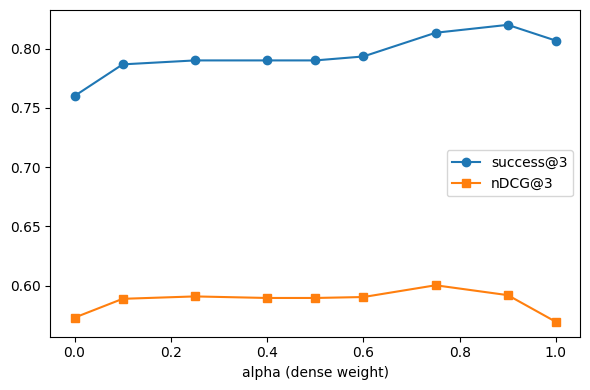

,success@k,ndcg@k,precision@k,recall@k,mrr,map
Embedding model,,,,,,
BAAI/bge-m3,0.8200,0.5011,0.2733,0.8200,0.3939,0.3939
intfloat/multilingual-e5-base,0.8100,0.5748,0.2700,0.8100,0.4956,0.4956
sentence-transformers/paraphrase-multilingual-mpnet-base-v2,0.5133,0.3504,0.1711,0.5133,0.2950,0.2950


In [42]:
sweep = []
for a in [0.0, 0.1, 0.25, 0.4, 0.5, 0.6, 0.75, 0.9, 1.0]:
    m = ab_eval(fusion="weighted", alpha=a)
    sweep.append({"alpha (dense weight)": a, "success@3": m["success@k"], "ndcg@3": m["ndcg@k"], "mrr": m["mrr"]})
alpha_sweep_df = pd.DataFrame(sweep).set_index("alpha (dense weight)")
display(alpha_sweep_df)

plt.figure(figsize=(6, 4))
plt.plot(alpha_sweep_df.index, alpha_sweep_df["success@3"], marker="o", label="success@3")
plt.plot(alpha_sweep_df.index, alpha_sweep_df["ndcg@3"], marker="s", label="nDCG@3")
plt.xlabel("alpha (dense weight)")
plt.legend()
plt.tight_layout()
plt.show()

emb_rows = []
for name in EMBEDDING_MODELS:
    m_, e_, ix_ = None, None, None
    try:
        m_ = load_with_retry(SentenceTransformer, name, device=str(device))
        e_ = m_.encode(ab_pool.texts, convert_to_numpy=True, batch_size=64, show_progress_bar=False)
        ix_ = build_faiss_index(e_)
        q = m_.encode(ab_claims, convert_to_numpy=True, batch_size=64, show_progress_bar=False)
        faiss.normalize_L2(q)
        _, idx = ix_.search(q, 3)
        ret = [[ab_pool.ids[j] for j in row] for row in idx]
        emb_rows.append({"Embedding model": name, **{k: round(v, 4) for k, v in evaluate_retrieval(ret, ab_relevant, 3).items()}})
    except Exception as e:
        print(f"Skipped {name}: {e}")
    finally:
        cleanup(m_, e_, ix_)

embedding_ablation_df = pd.DataFrame(emb_rows).set_index("Embedding model")
display(embedding_ablation_df)

In [43]:
ab_model_key = max(model_results, key=lambda k: model_results[k]["metrics"]["macro_f1"])
print(f"Ablation model: {ab_model_key}")

train_gold = train_df[COL_EVIDENCE].tolist()
dev_gold = dev_df[COL_EVIDENCE].tolist()

def ab_train_eval(model_key, tr_ev, dv_ev, loss_type="focal", epochs=AB_EPOCHS):
    set_seed(SEED)
    cfg = MODEL_CONFIGS[model_key]
    tok, model = load_tokenizer_and_model_with_retry(cfg["name"])
    model = model.to(device)

    counts = np.bincount(train_labels, minlength=2)
    w = torch.tensor([len(train_labels) / (2 * max(c, 1)) for c in counts], dtype=torch.float)

    class AbTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop("labels")
            out = model(**inputs)
            logits = out.logits
            wt = w.to(device=logits.device, dtype=logits.dtype)
            if loss_type == "focal":
                loss = FocalLoss(alpha=wt, gamma=2.0)(logits, labels)
            elif loss_type == "ce_weighted":
                loss = nn.CrossEntropyLoss(weight=wt)(logits, labels)
            else:
                loss = nn.CrossEntropyLoss()(logits, labels)
            return (loss, out) if return_outputs else loss

    tr_ds = VeracityDataset(train_claims, tr_ev, train_labels, tok, cfg["max_len"])
    dv_ds = VeracityDataset(dev_claims, dv_ev, dev_labels, tok, cfg["max_len"])
    args = TrainingArguments(
        output_dir="./tmp_ablation", num_train_epochs=epochs,
        per_device_train_batch_size=cfg["batch_size"], per_device_eval_batch_size=cfg["batch_size"] * 2,
        learning_rate=cfg["lr"], weight_decay=0.01, warmup_steps=30, lr_scheduler_type="cosine",
        fp16=False, eval_strategy="no", save_strategy="no", logging_strategy="no",
        report_to=[], seed=SEED,
    )
    trainer = AbTrainer(model=model, args=args, train_dataset=tr_ds, eval_dataset=dv_ds, tokenizer=tok)
    trainer.train()
    logits = np.nan_to_num(trainer.predict(dv_ds).predictions)
    pred = np.argmax(logits, axis=1)
    m = compute_classification_metrics(dev_labels, pred)
    cleanup(trainer, model, tok, tr_ds, dv_ds)
    return {"macro_f1": m["macro_f1"], "accuracy": m["accuracy"],
            "f1_SUPPORTS": m["f1_class_SUPPORTS"], "f1_REFUTES": m["f1_class_REFUTES"]}

top1_tr = [[e[0]] if e else [""] for e in train_evidences]
top1_dv = [[e[0]] if e else [""] for e in dev_evidences]

cls_experiments = {
    "No evidence (claim only), focal": (["" for _ in train_claims], ["" for _ in dev_claims], "focal"),
    "Retrieved top-1, focal": (top1_tr, top1_dv, "focal"),
    "Retrieved top-3 (FULL), focal": (train_evidences, dev_evidences, "focal"),
    "Gold evidence (upper bound), focal": (train_gold, dev_gold, "focal"),
    "Retrieved top-3, weighted CE": (train_evidences, dev_evidences, "ce_weighted"),
    "Retrieved top-3, plain CE": (train_evidences, dev_evidences, "ce"),
}

cls_rows = []
if AB_RUN_TRAINING:
    for name, (tr_ev, dv_ev, loss_type) in cls_experiments.items():
        print(f"Running: {name}")
        try:
            r = ab_train_eval(ab_model_key, tr_ev, dv_ev, loss_type)
            cls_rows.append({"Configuration": name, **{k: round(v, 4) for k, v in r.items()}})
        except Exception as e:
            print(f"  Failed: {e}")
        cleanup()

classification_ablation_df = pd.DataFrame(cls_rows).set_index("Configuration") if cls_rows else pd.DataFrame()
display(classification_ablation_df)

Ablation model: indicbert-v2
Running: No evidence (claim only), focal


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-only and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  0%|          | 0/852 [00:00<?, ?it/s]

  Failed: CUDA out of memory. Tried to allocate 734.00 MiB. GPU 0 has a total capacity of 14.84 GiB of which 138.62 MiB is free. Of the allocated memory 9.75 GiB is allocated by PyTorch, and 1.60 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)
Running: Retrieved top-1, focal


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-only and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  0%|          | 0/852 [00:00<?, ?it/s]

... (10 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-only and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  0%|          | 0/852 [00:00<?, ?it/s]

  Failed: CUDA out of memory. Tried to allocate 734.00 MiB. GPU 0 has a total capacity of 14.84 GiB of which 138.62 MiB is free. Of the allocated memory 9.75 GiB is allocated by PyTorch, and 1.60 GiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)


""


In [44]:
from itertools import combinations

ens_rows = []
keys = list(model_results.keys())

for k in keys:
    m = model_results[k]["metrics"]
    ens_rows.append({"Configuration": f"Single: {k}", "macro_f1": m["macro_f1"], "accuracy": m["accuracy"]})

for r in range(2, len(keys) + 1):
    for combo in combinations(keys, r):
        probs = [model_results[k]["dev_probs"] for k in combo]
        preds = [model_results[k]["dev_pred"] for k in combo]
        wts = [model_results[k]["metrics"]["macro_f1"] ** 2 for k in combo]
        variants = [("soft", soft_voting(probs)[0]), ("weighted", weighted_voting(probs, wts)[0])]
        if r >= 3:
            variants.append(("majority", majority_voting(preds)))
        for strat, p in variants:
            m = compute_classification_metrics(dev_labels, p)
            ens_rows.append({"Configuration": f"{strat}: {' + '.join(combo)}",
                             "macro_f1": m["macro_f1"], "accuracy": m["accuracy"]})

if len(keys) >= 3:
    for drop in keys:
        rest = [k for k in keys if k != drop]
        p = soft_voting([model_results[k]["dev_probs"] for k in rest])[0]
        m = compute_classification_metrics(dev_labels, p)
        ens_rows.append({"Configuration": f"Leave-one-out (soft), without {drop}",
                         "macro_f1": m["macro_f1"], "accuracy": m["accuracy"]})

ensemble_ablation_df = pd.DataFrame(ens_rows).set_index("Configuration").round(4).sort_values("macro_f1", ascending=False)
display(ensemble_ablation_df)

,macro_f1,accuracy
Configuration,,
Single: indicbert-v2,0.8036,0.8210
weighted: xlm-roberta-base + indicbert-v2,0.7943,0.8104
soft: xlm-roberta-base + indicbert-v2,0.7916,0.8069
Single: xlm-roberta-base,0.6540,0.6587


In [ ]:
dev_b_df = to_df(dev_b_raw)
print("dev_b columns:", list(dev_b_df.columns))

label_col = next((c for c in ["Label", "label", "Prediction", "prediction"] if c in dev_b_df.columns), None)
claim_col_b = next((c for c in ["Text", "claim", "Claim", "text"] if c in dev_b_df.columns), None)

def norm_label(x):
    x = str(x).strip().upper()
    return 0 if x.startswith("SUPPORT") else (1 if x.startswith("REFUTE") else None)

if label_col is None or claim_col_b is None:
    print("No usable label/claim column in dev_b; skipping Subtask 2 ablation.")
else:
    dv = dev_b_df[[claim_col_b, label_col]].copy()
    dv["y"] = dv[label_col].apply(norm_label)
    dv = dv.dropna(subset=["y"]).head(200).reset_index(drop=True)
    y_true = dv["y"].astype(int).tolist()
    claims_b = dv[claim_col_b].astype(str).apply(clean_text).tolist()

    def ab_retrieve_texts(claim, k):
        qe = ab_dense.encode([claim], convert_to_numpy=True, show_progress_bar=False)
        faiss.normalize_L2(qe)
        sc, ix = ab_index.search(qe, AB_K)
        dense = [(ab_pool.ids[j], float(s)) for j, s in zip(ix[0], sc[0])]
        b = ab_bm25.get_scores(tokenize_simple(claim))
        bt = np.argsort(b)[::-1][:AB_K]
        sparse = [(ab_pool.ids[j], float(b[j])) for j in bt]
        cands = ab_dedup(ab_rrf(dense, sparse))[:15]
        s = ab_reranker.predict([(claim, ab_pool.get(e)) for e in cands], show_progress_bar=False)
        order = [e for e, _ in sorted(zip(cands, s), key=lambda x: x[1], reverse=True)]
        return [ab_pool.get(e) for e in order[:k]]

    heur_label = lambda claim, summ: 1 if verify_label(claim, summ) == "REFUTES" else 0
    s2_rows = []

    maj = int(np.bincount(y_true).argmax())
    m = compute_classification_metrics(y_true, [maj] * len(y_true))
    s2_rows.append({"Configuration": "Majority-class baseline", "macro_f1": m["macro_f1"], "accuracy": m["accuracy"]})

    for k in [1, 3, 5]:
        preds = []
        for c in tqdm(claims_b, desc=f"heuristic k={k}"):
            summ = extractive_fallback_summary(ab_retrieve_texts(c, k))
            preds.append(heur_label(c, summ))
        m = compute_classification_metrics(y_true, preds)
        s2_rows.append({"Configuration": f"Lexical heuristic, top-{k} evidence", "macro_f1": m["macro_f1"], "accuracy": m["accuracy"]})

    best_name = top_approaches[0]
    ev3 = [ab_retrieve_texts(c, 3) for c in tqdm(claims_b, desc="retrieve top-3 for classifier")]
    p = predict_with_approach(best_name, claims_b, ev3)
    m = compute_classification_metrics(y_true, p)
    s2_rows.append({"Configuration": f"Trained classifier ({best_name}), top-3 evidence", "macro_f1": m["macro_f1"], "accuracy": m["accuracy"]})

    subtask2_ablation_df = pd.DataFrame(s2_rows).set_index("Configuration").round(4)
    display(subtask2_ablation_df)

dev_b columns: ['ID', 'Text', 'Label']


heuristic k=1:   0%|          | 0/200 [00:00<?, ?it/s]

heuristic k=3:   0%|          | 0/200 [00:00<?, ?it/s]

heuristic k=5:   0%|          | 0/200 [00:00<?, ?it/s]

retrieve top-3 for classifier:   0%|          | 0/200 [00:00<?, ?it/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ai4bharat/IndicBERTv2-MLM-only and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Inference [indicbert-v2]:   0%|          | 0/7 [00:00<?, ?it/s]

,macro_f1,accuracy
Configuration,,
Majority-class baseline,0.4048,0.680
"Lexical heuristic, top-1 evidence",0.4813,0.515
"Lexical heuristic, top-3 evidence",0.4875,0.540
"Lexical heuristic, top-5 evidence",0.4875,0.545
"Trained classifier (indicbert-v2), top-3 evidence",0.2405,0.300


: 